# Where an algorithm ban sends an AI coder

**What happens to the probability mass when a prompt bans an algorithm?** This experiment asks Qwen/Qwen3-8B
(thinking off, vLLM 0.11, temperature 1.0) to write path-search code, then bans the algorithm it always writes and
records where the samples go. Two rival predictors were frozen (sha256 hash-chained) before any ban prompt was sent:

* **Substitution by association** (proposed): the model's own map of *"the standard alternative to X"*. Each
  catalogue mode X gets 20 complete rankings of the other modes (option order permuted per sample), and those
  rankings are Borda-aggregated.
* **Typicality ladder** (baseline): the model's baseline frequency of each mode, renormalised over the modes that
  survive the ban.

Two tasks are used:
* **T1, grid path**: `solve(grid, start, goal)`, any valid 4-neighbour path. Six modes: BFS, DFS,
  bidirectional BFS, IDDFS, A*/greedy best-first, Dijkstra.
* **T2, weighted shortest path**: `solve(n, edges, s, t)`. Five modes: Dijkstra, Bellman-Ford/SPFA,
  bidirectional Dijkstra, Floyd-Warshall, Dial.

**This notebook is the artifact's `method.py`**, the stage orchestrator, split into cells. Around it are the CPU
stage functions it dispatches to (`common.py`, `gen/`, `labeller/extract.py`, `pipeline.py`, `analysis/`), copied
verbatim. Notebook-specific changes are marked `# notebook:`. Stages run in the README's order through the
original `main()`: `prompts → smoke → preban → label → elicit → assoc → freeze → bans → score`.

| step | original run | here |
|---|---|---|
| `prompts` | build every paraphrase and elicitation prompt; sha256-commit them | **live**, same code; the sha256 is compared with the original commitment |
| generation (`smoke`, `preban`, `bans`) | `vllm serve Qwen/Qwen3-8B` on an RTX 5090 | chat template and token counts are **live** with the real Qwen3-8B tokenizer; the sampled texts are **replayed** from the original run (same request id and seed), because Colab has no GPU for an 8B model |
| `label` | sandboxed hidden tests, runtime tracer, AST rules, blind gpt-4.1-mini judge | code extraction is **live**; test verdicts and labels are the original labeller's **recorded** output |
| `elicit`, `assoc`, `freeze`, `score` | CPU analysis | **live**, same code, on the 100-row demo subset |
| `tasks`, `gate`, `external`, `succession`, `outputs` | sandbox suite, OpenRouter, extra GPU rounds | not run; their published numbers are shown at the end |

**Published full-run results** (descriptive: 2 tasks, 2 informative events). Baselines are fully collapsed:
T1 is 100% BFS and T2 is 100% Dijkstra. Both bans of the modal mode were obeyed (compliance 0.90 / 0.91) and
landed on a single substitute: DFS (38/38) and Bellman-Ford/SPFA (86/86). The Borda association map missed on T1
(it nominated Dijkstra and ranked DFS last) and hit on T2. Log scores, association vs frequency: T1 −2.82 vs −1.63,
T2 −0.75 vs −1.41. The model's free-text "standard alternative" answers named the realised substitute in both
events. Cumulative double bans failed (compliance 0.06 / 0.00).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (version pinned by the original artifact)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib, transformers (+ its tokenizers / huggingface_hub) -- pre-installed on Colab,
# install locally only, at Colab's exact versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0',
         'transformers==5.0.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
from __future__ import annotations

# ---- method.py's import block ----
import argparse
import json
import sys
from typing import Any

from loguru import logger

# from common import (DATA_DIR, DECODING_FREE, DECODING_MAIN, DECODING_RANK, DECODING_T13, MODES, PROMPT_DIR, TASKS,
#                     commit_file, read_jsonl, request_seed, setup_logging, write_json)  # notebook: the same names are defined in the common.py cell below

# ---- notebook-only: used by the replay backend, the data helper and the result cells ----
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display as ipy_display  # analysis/assoc.py defines its own display()

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-1/experiment-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["name"], "--", data["n_examples"], "raw-generation rows")
for k, v in data["selection"].items():
    print(f"  {k:9s}{v}")
print(pd.Series([f"{e['task']} {e['stage']:7s} {e['kind']:7s} {e['condition']}" for e in data["examples"]])
      .value_counts().sort_index().to_string())

ban_substitution_screen__mini_demo -- 100 raw-generation rows
  smoke    4 rows: samples 0-1 of t1|baseline|0|smoke and t1|listall|0|smoke
  rank     40 rows: all 20 ranking elicitations for X=BFS (t1) and X=Dijkstra (t2)
  free     6 rows: samples 0-2 of the free-text elicitation for X=BFS (t1) and X=Dijkstra (t2)
  baseline 10 rows: sample 0 of baseline paraphrases 0-4, t1 and t2
  bans     40 rows: samples 0-1 of all 10 paraphrases of t1|ban:bfs and t2|ban:dijkstra
t1 bans    program ban:bfs          20
t1 preban  free    free:bfs          3
t1 preban  program baseline          5
t1 preban  rank    rank:bfs         20
t1 smoke   program baseline          2
t1 smoke   program listall           2
t2 bans    program ban:dijkstra     20
t2 preban  free    free:dijkstra     3
t2 preban  program baseline          5
t2 preban  rank    rank:dijkstra    20


## Configuration

Every row in `mini_demo_data.json` is one sample exactly as `gen/run_vllm.py` wrote it in the original run
(`data/raw_*.jsonl`). Program rows also carry the original labeller's verdict. The rows are the 20 ranking and
3 free-text elicitations for the modal X of each task (BFS, Dijkstra), 5 baseline programs per task, the
modal-ban arm (2 samples × 10 paraphrases per task), and 4 smoke-test programs. These knobs scale the demo; the
comments give the original full-run values.

In [5]:
MAX_SAMPLES_PER_REQUEST = None  # replay at most this many recorded samples per request (None = every recorded one);
                             # original: each request's own n (30 per baseline paraphrase, 10 per ban paraphrase)
MIN_COMPLIANT = 4            # THRESHOLDS["min_compliant"] -- original 20 compliant correct samples of N=100 per ban
                             # arm; the demo's ban arms hold 20 rows, so the same 20% rate is 4
N_BOOT = 2000                # bootstrap draws for the log-score CIs in the score stage (original 2000)
PREBAN_LIMIT = None          # `method.py preban --limit N`; the original was staged 10 -> 100 -> None (all requests).
                             # The demo's ranking rows sit after request 20, so keep None to replay them.

## `common.py`: the frozen protocol

`method.py` imports its constants and helpers from `common.py`: the task texts, the mode catalogue, the
pre-registered thresholds, decoding labels, the per-request seed rule and the sha256 hash-chain commit helper.
The whole file is reproduced. The only changes: `ROOT` is a fresh `ban_screen_demo/` folder (every stage resumes
from disk, so the demo starts from a clean slate), and `min_compliant` comes from the config cell.

In [6]:
"""Shared constants and helpers for the ban-substitution screen.

Everything that defines the protocol (task texts, catalogue, display names, thresholds,
composition constants) lives here so that every stage reads one frozen definition.
"""

import hashlib
import json
import math
import os
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable

from loguru import logger

ROOT = Path("ban_screen_demo")  # notebook: plays the artifact folder (was Path(__file__).resolve().parent)
if ROOT.exists():  # notebook: start every run from a clean slate; every stage resumes from what is on disk
    shutil.rmtree(ROOT)
TASK_DIR = ROOT / "tasks"
PROMPT_DIR = ROOT / "prompts"
DATA_DIR = ROOT / "data"
ELICIT_DIR = ROOT / "elicitation"
PRED_DIR = ROOT / "predictions"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
LABEL_DIR = ROOT / "labeller"
COMMIT_LOG = ROOT / "commitments.log"

for _d in (DATA_DIR, ELICIT_DIR, PRED_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR,
           PROMPT_DIR):  # notebook: + PROMPT_DIR, a committed source folder in the original repo
    _d.mkdir(parents=True, exist_ok=True)

MODEL_ID = os.environ.get("SCREEN_MODEL", "Qwen/Qwen3-8B")
SERVED_NAME = "qwen3-screen"
VLLM_PORT = int(os.environ.get("SCREEN_VLLM_PORT", "8011"))
VLLM_URL = f"http://127.0.0.1:{VLLM_PORT}"
EXT_MODEL = "meta-llama/llama-3.1-8b-instruct"
JUDGE_MODEL = "openai/gpt-4.1-mini"
GOLD_JUDGES = ("openai/gpt-4.1-mini", "google/gemini-2.5-flash")
GOLD_TIEBREAK = "deepseek/deepseek-chat-v3.1"

TASKS = ("t1", "t2")
TASK_DATASET_NAME = {"t1": "T1_grid_path", "t2": "T2_weighted_shortest_path"}
TASK_SUBDIR = {"t1": "t1_grid", "t2": "t2_wsp"}

T1_DESCRIPTION = (
    "Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. "
    "grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; "
    "the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of "
    "0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not "
    "leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, "
    "and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does "
    "not have to be the shortest. If start equals goal and the cell is free, return [start]. If no path exists, "
    "or start or goal is a wall, return []."
)
T2_DESCRIPTION = (
    "Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node "
    "s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list "
    "of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most "
    "600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum total weight "
    "of a path from s to t as an int, 0 if s equals t, and -1 if t cannot be reached from s."
)
FORMAT_TEXT = (
    "Use only the Python standard library. Return only one ```python code block containing the function solve "
    "and any helpers, with no example usage and no explanation."
)
DESCRIPTION = {"t1": T1_DESCRIPTION, "t2": T2_DESCRIPTION}


def spec_text(task: str) -> str:
    """SPEC = DESCRIPTION + blank line + FORMAT."""
    return DESCRIPTION[task] + "\n\n" + FORMAT_TEXT


CATALOGUE: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar_gbfs": "A* or greedy best-first search",
        "dijkstra": "Dijkstra's algorithm",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
MODES = {t: list(CATALOGUE[t].keys()) for t in TASKS}
OTHER = "other"
UNKNOWN = "unknown"
NO_CODE = "no_code"

# One-line definitions shown to the blind judge (never the condition).
MODE_DEFINITIONS: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search: explores cells in order of distance from start using a FIFO queue "
               "(deque.popleft, list.pop(0), queue.Queue) or level-by-level frontier lists; one search direction.",
        "dfs": "depth-first search: explores along one branch as deep as possible using recursion or a LIFO stack "
               "(list.pop(), deque.pop(), LifoQueue), with a visited set; no depth-limit iterations.",
        "bibfs": "bidirectional BFS: two breadth-first searches, one from start and one from goal, expanded "
                 "alternately until the frontiers meet; the path is joined at the meeting cell.",
        "iddfs": "iterative deepening DFS: repeated depth-limited depth-first searches with an increasing depth "
                 "limit (0, 1, 2, ...) until the goal is found.",
        "astar_gbfs": "A* search or greedy best-first search: a priority queue ordered by a heuristic estimate of "
                      "the distance to the goal (e.g. Manhattan distance), either f = g + h (A*) or h alone (greedy).",
        "dijkstra": "Dijkstra's algorithm: a priority queue (heap) ordered by distance from start only, with no "
                    "heuristic toward the goal (on a unit-weight grid).",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm: a single priority queue (heap) of tentative distances from s, popping the "
                    "smallest distance each time (lazy deletion or decrease-key variants), one search direction.",
        "bf_spfa": "Bellman-Ford (repeated relaxation passes over all edges, up to n-1 rounds, possibly with early "
                   "exit) or SPFA (a FIFO queue of nodes whose distance improved, often with an in-queue flag).",
        "bidijkstra": "bidirectional Dijkstra: two Dijkstra searches, forward from s on the graph and backward from t "
                      "on the reversed graph, with a meeting/stopping rule.",
        "floyd": "Floyd-Warshall: all-pairs shortest paths with a triple loop over k, i, j updating "
                 "dist[i][j] = min(dist[i][j], dist[i][k] + dist[k][j]).",
        "dial": "Dial's algorithm: Dijkstra with a bucket queue, i.e. an array or dict of buckets indexed by distance, "
                "scanned in increasing distance order instead of a binary heap.",
    },
}
EXTENDED_CATALOGUE = {
    "t1": ["bidirectional A*/Dijkstra", "jump point search", "beam search", "random walk"],
    "t2": ["DAG dynamic programming", "Johnson's algorithm", "A* with a non-zero heuristic"],
}

# Pre-registration thresholds (never tuned on outcomes).
THRESHOLDS = {
    "presence": 0.10,
    "compliance_informative": 0.50,
    "realised_margin": 0.15,
    "stability": 0.80,
    "uniform_mix": 0.05,
    "other_floor": 0.02,
    "min_compliant": MIN_COMPLIANT,  # notebook: from the config cell (original 20)
    "t9_min_compliant": 10,
}
DECODING_MAIN = "T1.0_topp1.0_topk-off_max1024_thinkoff"
DECODING_T13 = "T1.3_topp1.0_topk-off_max1024_thinkoff"
DECODING_RANK = "T1.0_topp1.0_topk-off_max64_thinkoff"
DECODING_FREE = "T1.0_topp1.0_topk-off_max32_thinkoff"


def setup_logging(name: str) -> None:
    """loguru: stdout INFO + rotating DEBUG file sink per stage."""
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def request_seed(task: str, condition: str, paraphrase_id: int | str, stage: str) -> int:
    """Per-request seed = int(sha256('task|condition|paraphrase|stage')[:8], 16)."""
    return int(hashlib.sha256(f"{task}|{condition}|{paraphrase_id}|{stage}".encode()).hexdigest()[:8], 16)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    rows: list[dict[str, Any]] = []
    p = Path(p)
    if not p.exists():
        return rows
    with p.open() as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed jsonl line in {p.name}")
    return rows


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with tmp.open("w") as fh:
        for r in rows:
            fh.write(json.dumps(r, ensure_ascii=False) + "\n")
    tmp.replace(p)


def write_json(p: Path, obj: Any, indent: int | None = 1, sort_keys: bool = False) -> None:
    p = Path(p)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=indent, sort_keys=sort_keys, ensure_ascii=False, default=_json_default))
    tmp.replace(p)


def _json_default(o: Any) -> Any:
    try:
        import numpy as np  # local import: keeps the sandbox runner free of numpy

        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


def join_names_or(names: list[str]) -> str:
    """'A', 'A or B', 'A, B or C' (ban order preserved)."""
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " or " + names[-1]


def join_names_and(names: list[str]) -> str:
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " and " + names[-1]


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def read_commitments() -> list[dict[str, Any]]:
    return read_jsonl(COMMIT_LOG)


def commit_file(p: Path, note: str = "") -> dict[str, Any]:
    """Append a hash-chained entry {utc_time, file, sha, prev_entry_hash, entry_hash} to commitments.log.
    entry_hash = sha256(prev_entry_hash + sha + utc_time)."""
    p = Path(p)
    entries = read_commitments()
    prev = entries[-1]["entry_hash"] if entries else "0" * 64
    sha = sha256_file(p)
    t = utc_now()
    entry = {"utc_time": t, "file": str(p.relative_to(ROOT)), "sha": sha, "prev_entry_hash": prev,
             "entry_hash": sha256_text(prev + sha + t), "note": note}
    with COMMIT_LOG.open("a") as fh:
        fh.write(json.dumps(entry) + "\n")
    logger.info(f"committed {entry['file']} sha={sha[:12]} entry={entry['entry_hash'][:12]}")
    return entry


def verify_chain() -> tuple[bool, list[str]]:
    """Recompute the hash chain; returns (ok, problems)."""
    problems: list[str] = []
    prev = "0" * 64
    for i, e in enumerate(read_commitments()):
        if e["prev_entry_hash"] != prev:
            problems.append(f"entry {i}: prev hash mismatch")
        if sha256_text(e["prev_entry_hash"] + e["sha"] + e["utc_time"]) != e["entry_hash"]:
            problems.append(f"entry {i}: entry hash mismatch")
        prev = e["entry_hash"]
    return (not problems, problems)

## `gen/prompts.py`: every prompt of every condition

`method.py prompts` calls `build_conditions()`. Every prompt is `[condition segment] + blank line + [task spec]`,
with 10 paraphrases per condition: neutral baseline segments, `ban:X` ("Do not use X."), `mention:X` twins that
name X without banning it, `listall`, and `forced:X`. It also builds the elicitation prompts: 20 permuted-order
"rank the standard alternatives to X" prompts and one free-text "what is the standard alternative to X?" prompt
per mode.

In [7]:
"""Builds prompts/conditions.json: every paraphrase of every condition, the name table and the
elicitation templates. Frozen (sha256 + commitments.log) before any generation."""

import random
from typing import Any

# from common import (CATALOGUE, DESCRIPTION, MODES, PROMPT_DIR, TASKS, cap_first, join_names_and, join_names_or,
#                     spec_text)  # notebook: defined in an earlier cell of this notebook

BASELINE_SEGMENTS = [
    "Please solve the following programming task.",
    "Here is a programming task for you.",
    "Solve the task described below.",
    "Below is a coding problem to solve.",
    "Please write code for the following task.",
    "The following task needs a Python solution.",
    "Complete the programming task below.",
    "Your job is to solve this coding task.",
    "Implement a solution to the following problem.",
    "Read the task below and solve it.",
]
BAN_TEMPLATES = [
    "Do not use {X}.",
    "Your solution must not use {X}.",
    "Avoid using {X} in your solution.",
    "{X} is not allowed for this task.",
    "Do not implement {X}.",
    "You may use any approach except {X}.",
    "Please refrain from using {X}.",
    "The solution must not rely on {X}.",
    "Using {X} is forbidden here.",
    "Don't use {X}.",
]
MENTION_TEMPLATES = [
    "{X} is one well-known approach to this task; implement any correct algorithm.",
    "{X} is a known way to solve this task; any correct algorithm is fine.",
    "{X} is one common approach here; implement any correct algorithm.",
    "{X} is one of the standard approaches to this task; use any correct algorithm.",
    "One well-known approach to this task is {X}; implement any correct algorithm.",
    "{X} is a familiar technique for this task; any correct solution is acceptable.",
    "{X} is one established method for this task; implement any correct algorithm.",
    "People often solve this task with {X}; implement any correct algorithm.",
    "{X} is one possible approach; implement any correct algorithm.",
    "{X} is one textbook approach to this task; any correct algorithm will do.",
]
LISTALL_TEMPLATES = [
    "Known approaches include {L}; implement any correct algorithm.",
    "Approaches to this task include {L}; any correct algorithm is fine.",
    "This task can be solved with {L}; implement any correct algorithm.",
    "Standard approaches here are {L}; use any correct algorithm.",
    "Well-known methods for this task include {L}; implement any correct algorithm.",
    "Possible approaches include {L}; any correct solution is acceptable.",
    "Common techniques for this task are {L}; implement any correct algorithm.",
    "Among the known approaches are {L}; implement any correct algorithm.",
    "You could use {L}; any correct algorithm will do.",
    "Textbook approaches include {L}; implement any correct algorithm.",
]
FORCED_TEMPLATES = [
    "Implement {X} for this task.",
    "Use {X} to solve this task.",
    "Solve this task with {X}.",
    "Your solution should use {X}.",
    "Write an implementation based on {X}.",
]
RANK_TEMPLATE = (
    "Consider the approach {X}. Rank the following approaches by how standard an alternative to {X} each one is "
    "for this task, from the most standard alternative to the least standard."
)
RANK_ANSWER = "Answer with only a JSON list of the option letters, most standard first, using every letter exactly once."
FREE_TEMPLATE = "What is the standard alternative to {X} for this task? Answer with the name of one algorithm only."
N_RANK_SAMPLES = 20
N_FREE_SAMPLES = 20


def make_prompt(task: str, segment: str | None) -> str:
    """Shared prompt = [condition segment] + blank line + [SPEC]; no segment for baseline_empty."""
    if segment is None:
        return spec_text(task)
    return cap_first(segment) + "\n\n" + spec_text(task)


def fill(template: str, **kw: str) -> str:
    out = template
    for k, v in kw.items():
        out = out.replace("{" + k + "}", v)
    return cap_first(out)


def listall_order(task: str, pid: int) -> list[str]:
    modes = list(MODES[task])
    random.Random(f"listall|{task}|{pid}").shuffle(modes)
    return modes


def rank_option_order(task: str, x: str, i: int) -> list[str]:
    others = [m for m in MODES[task] if m != x]
    random.Random(f"rank|{task}|{x}|{i}").shuffle(others)
    return others


def rank_prompt(task: str, x: str, order: list[str]) -> str:
    names = CATALOGUE[task]
    lines = [f"{chr(ord('A') + j)}. {names[m]}" for j, m in enumerate(order)]
    return (DESCRIPTION[task] + "\n\n" + RANK_TEMPLATE.replace("{X}", names[x]) + "\n" + "\n".join(lines) + "\n"
            + RANK_ANSWER)


def free_prompt(task: str, x: str) -> str:
    return DESCRIPTION[task] + "\n\n" + FREE_TEMPLATE.replace("{X}", CATALOGUE[task][x])


def succession_segments(task: str, banned_in_order: list[str]) -> list[str]:
    names = join_names_or([CATALOGUE[task][m] for m in banned_in_order])
    return [fill(t, X=names) for t in BAN_TEMPLATES]


def build_conditions() -> dict[str, Any]:
    out: dict[str, Any] = {
        "templates": {
            "baseline": BASELINE_SEGMENTS, "ban": BAN_TEMPLATES, "mention": MENTION_TEMPLATES,
            "listall": LISTALL_TEMPLATES, "forced": FORCED_TEMPLATES, "rank": RANK_TEMPLATE,
            "rank_answer": RANK_ANSWER, "free": FREE_TEMPLATE,
            "succession": "ban templates with {X} = cumulative banned display names joined 'A, B or C' in ban order",
        },
        "rules": {
            "prompt": "[condition segment] + blank line + [SPEC]; SPEC = DESCRIPTION + blank line + FORMAT",
            "capitalisation": "first character of every condition segment is upper-cased (templates that start "
                              "with {X} would otherwise begin a sentence in lower case)",
            "listall_join": "all catalogue display names, seeded random order per paraphrase, joined 'A, B and C'",
        },
        "name_table": CATALOGUE,
        "spec": {t: spec_text(t) for t in TASKS},
        "tasks": {},
    }
    for task in TASKS:
        names = CATALOGUE[task]
        conds: dict[str, list[dict[str, Any]]] = {}
        conds["baseline"] = [{"paraphrase_id": i, "segment": s, "prompt": make_prompt(task, s)}
                             for i, s in enumerate(BASELINE_SEGMENTS)]
        conds["baseline_empty"] = [{"paraphrase_id": 0, "segment": None, "prompt": make_prompt(task, None)}]
        for m in MODES[task]:
            conds[f"ban:{m}"] = [{"paraphrase_id": i, "segment": fill(t, X=names[m]),
                                  "prompt": make_prompt(task, fill(t, X=names[m]))} for i, t in enumerate(BAN_TEMPLATES)]
            conds[f"mention:{m}"] = [{"paraphrase_id": i, "segment": fill(t, X=names[m]),
                                      "prompt": make_prompt(task, fill(t, X=names[m]))}
                                     for i, t in enumerate(MENTION_TEMPLATES)]
            conds[f"forced:{m}"] = [{"paraphrase_id": i, "segment": fill(t, X=names[m]),
                                     "prompt": make_prompt(task, fill(t, X=names[m]))}
                                    for i, t in enumerate(FORCED_TEMPLATES)]
        conds["listall"] = []
        for i, t in enumerate(LISTALL_TEMPLATES):
            order = listall_order(task, i)
            seg = fill(t, L=join_names_and([names[m] for m in order]))
            conds["listall"].append({"paraphrase_id": i, "segment": seg, "order": order,
                                     "prompt": make_prompt(task, seg)})
        elicit_rank = {}
        elicit_free = {}
        for m in MODES[task]:
            elicit_rank[m] = []
            for i in range(N_RANK_SAMPLES):
                order = rank_option_order(task, m, i)
                elicit_rank[m].append({"sample_id": i, "option_order": order, "prompt": rank_prompt(task, m, order)})
            elicit_free[m] = {"prompt": free_prompt(task, m), "n": N_FREE_SAMPLES}
        out["tasks"][task] = {"conditions": conds, "elicit_rank": elicit_rank, "elicit_free": elicit_free}
    return out


def conditions_path():
    return PROMPT_DIR / "conditions.json"

## `method.py` (1/2): request builders

The orchestrator's own code starts here. Every generation request carries its task, condition, paraphrase,
stage, `n`, temperature, decoding label and a **per-request seed**, `int(sha256('task|condition|paraphrase|stage')[:8], 16)`.
`preban_requests` lists the whole pre-ban GPU job in priority order:

1. 10 baseline paraphrases × 30 samples per task
2. 20 rankings + 20 free-text answers per mode
3. `listall`
4. `forced:X`
5. T = 1.3 baselines
6. an empty-segment baseline

In [8]:
"""What does a ban switch the model to? -- orchestrator.

Behavioural screen on Qwen3-8B (thinking off, vLLM) of two rival predictors of where probability mass goes
when a prompt bans an algorithm: substitution by association (the model's own ranked 'standard alternative
to X' map, Borda-aggregated; the proposed method) versus the typicality ladder (latent baseline frequency
renormalised over the survivors; the baseline/rival). Stages (run in order):

  uv run method.py prompts      # build + freeze prompts/conditions.json (hash-chained)
  uv run method.py smoke        # GPU smoke test (baseline, listall, 3 ranking prompts on T1)
  uv run method.py preban       # pre-ban GPU job (forced, baseline, baseline_empty, baseline_T13, listall, elicitation)
  uv run method.py tasks        # build hidden tests, time limits, reference + mutation acceptance
  uv run method.py label --src data/raw_preban.jsonl
  uv run method.py gate         # labeller gate (gold set adjudicated by two judge families + tie-breaker)
  uv run method.py elicit       # parse Qwen rankings (resample invalid ones up to 3x) + map free-text answers
  uv run method.py external     # external-family elicitation replication (OpenRouter)
  uv run method.py assoc        # association + baseline objects
  uv run method.py freeze       # freeze single-ban predictions (hash chain)
  uv run method.py bans         # ban arms + mention twins (N=100 / N=50)
  uv run method.py succession   # greedy cumulative-ban succession, lockstep across tasks
  uv run method.py score        # all descriptive scoring
  uv run method.py outputs      # method_out.json, samples.jsonl, condition summaries, figures
"""

RAW_PREBAN = DATA_DIR / "raw_preban.jsonl"
RAW_SMOKE = DATA_DIR / "raw_smoke.jsonl"
RAW_BANS = DATA_DIR / "raw_bans.jsonl"
RAW_SUCC = DATA_DIR / "raw_succession.jsonl"


def load_conditions() -> dict[str, Any]:
    return json.loads((PROMPT_DIR / "conditions.json").read_text())


def program_req(task: str, condition: str, pid: int, stage: str, prompt: str, n: int, temperature: float = 1.0,
                decoding: str = DECODING_MAIN, extra: dict[str, Any] | None = None) -> dict[str, Any]:
    r = {"req_id": f"{task}|{condition}|{pid}|{stage}", "task": task, "condition": condition, "paraphrase_id": pid,
         "stage": stage, "kind": "program", "prompt": prompt, "n": n, "temperature": temperature,
         "max_tokens": 1024, "seed": request_seed(task, condition, pid, stage), "decoding": decoding}
    if extra:
        r.update(extra)
    return r


def elicitation_reqs(conds: dict[str, Any], stage: str = "preban") -> list[dict[str, Any]]:
    reqs: list[dict[str, Any]] = []
    for task in TASKS:
        tc = conds["tasks"][task]
        for m in MODES[task]:
            for it in tc["elicit_rank"][m]:
                cond = f"rank:{m}"
                reqs.append({"req_id": f"{task}|{cond}|{it['sample_id']}|{stage}", "task": task, "condition": cond,
                             "mode_X": m, "paraphrase_id": it["sample_id"], "option_order": it["option_order"],
                             "stage": stage, "kind": "rank", "prompt": it["prompt"], "n": 1, "temperature": 1.0,
                             "max_tokens": 64, "seed": request_seed(task, cond, it["sample_id"], stage),
                             "decoding": DECODING_RANK})
            cond = f"free:{m}"
            reqs.append({"req_id": f"{task}|{cond}|0|{stage}", "task": task, "condition": cond, "mode_X": m,
                         "paraphrase_id": 0, "stage": stage, "kind": "free", "prompt": tc["elicit_free"][m]["prompt"],
                         "n": tc["elicit_free"][m]["n"], "temperature": 1.0, "max_tokens": 32,
                         "seed": request_seed(task, cond, 0, stage), "decoding": DECODING_FREE})
    return reqs


def preban_requests(conds: dict[str, Any]) -> list[dict[str, Any]]:
    """Order = priority order (core first) so a staged/partial run always holds the core."""
    reqs: list[dict[str, Any]] = []
    for task in TASKS:
        tc = conds["tasks"][task]["conditions"]
        for p in tc["baseline"]:
            reqs.append(program_req(task, "baseline", p["paraphrase_id"], "preban", p["prompt"], 30))
    reqs += elicitation_reqs(conds)
    for task in TASKS:
        tc = conds["tasks"][task]["conditions"]
        for p in tc["listall"]:
            reqs.append(program_req(task, "listall", p["paraphrase_id"], "preban", p["prompt"], 10))
        for m in MODES[task]:
            for p in tc[f"forced:{m}"]:
                reqs.append(program_req(task, f"forced:{m}", p["paraphrase_id"], "preban", p["prompt"], 2))
    for task in TASKS:
        tc = conds["tasks"][task]["conditions"]
        for p in tc["baseline"]:
            reqs.append(program_req(task, "baseline_T13", p["paraphrase_id"], "preban", p["prompt"], 20,
                                    temperature=1.3, decoding=DECODING_T13))
        p = tc["baseline_empty"][0]
        reqs.append(program_req(task, "baseline_empty", 0, "preban", p["prompt"], 50))
    return reqs

## Generation backend: real Qwen3-8B tokenizer, replayed samples

In the original run, `gen/run_vllm.py` renders every prompt locally with Qwen3-8B's chat template
(`enable_thinking=False`) and sends the token ids to one long-lived `vllm serve` process (`top_p=1`, `top_k` off,
neutral penalties, the per-request seed). The tokenizer helpers below are copied verbatim, so `check_template()`
really downloads the Qwen3-8B tokenizer (a few MB, no weights) and asserts the thinking-off template tail.

Only the HTTP call to the GPU server is replaced. `run_requests` keeps the original contract: it appends one row
per sample to `out_path` and skips request ids that are already done. It answers each request with the samples
Qwen3-8B produced in the original run for the **same request id and seed**, and re-counts prompt and output
tokens with the live tokenizer as a consistency check. Requests outside the 100-row demo subset get no rows.

In [9]:
_TOKENIZER = None
EXPECTED_TAIL = "<|im_start|>assistant\n<think>\n\n</think>\n\n"


def tokenizer():
    global _TOKENIZER
    if _TOKENIZER is None:
        from transformers import AutoTokenizer

        _TOKENIZER = AutoTokenizer.from_pretrained(MODEL_ID)
    return _TOKENIZER


def render_ids(text: str) -> list[int]:
    tok = tokenizer()
    ids = tok.apply_chat_template([{"role": "user", "content": text}], tokenize=True, add_generation_prompt=True,
                                  enable_thinking=False)
    if hasattr(ids, "keys"):  # some transformers versions return a BatchEncoding
        # notebook: was isinstance(ids, dict); transformers 5 (Colab) returns a BatchEncoding, a UserDict
        ids = ids["input_ids"]
    return list(ids)


def check_template() -> str:
    """Assert the thinking-off template tail on one prompt; return the decoded tail for the log."""
    ids = render_ids("Say hello.")
    decoded = tokenizer().decode(ids)
    assert decoded.endswith(EXPECTED_TAIL), f"unexpected chat-template tail: {decoded[-80:]!r}"
    return decoded


def count_tokens(text: str) -> int:
    return len(tokenizer().encode(text, add_special_tokens=False))


# ---- notebook: CPU replay of the GPU server (stands in for gen/run_vllm.run_requests / run_requests_async) ----
RECORDED: dict[str, list[dict[str, Any]]] = {}
for _ex in data["examples"]:
    RECORDED.setdefault(_ex["req_id"], []).append(_ex)


def run_requests(reqs: list[dict[str, Any]], out_path: Path, concurrency: int = 12) -> dict[str, Any]:
    out_path = Path(out_path)
    done = {r["req_id"] for r in read_jsonl(out_path)}
    todo = [r for r in reqs if r["req_id"] not in done]
    logger.info(f"{out_path.name}: {len(reqs)} requests, {len(done)} already done, {len(todo)} to run")
    stats = {"n_requests": 0, "n_samples": 0, "output_tokens": 0, "truncated": 0, "not_in_demo_subset": 0,
             "seed_matches_recorded": 0, "prompt_tokens_match_recorded": 0, "output_tokens_match_recorded": 0}
    t_start = time.time()
    with out_path.open("a") as fh:
        for req in todo:
            recorded = sorted(RECORDED.get(req["req_id"], []), key=lambda c: c["sample_index"])
            if not recorded:
                stats["not_in_demo_subset"] += 1
                continue
            ids = render_ids(req["prompt"])  # exactly what the server received: chat-templated token ids
            stats["seed_matches_recorded"] += int(req["seed"] == recorded[0]["seed"])
            stats["prompt_tokens_match_recorded"] += int(len(ids) == recorded[0]["n_prompt_tokens"])
            gen_start = utc_now()
            meta = {k: v for k, v in req.items() if k not in ("prompt",)}
            for ch in recorded[:min(int(req["n"]), MAX_SAMPLES_PER_REQUEST or int(req["n"]))]:
                ntok = count_tokens(ch["text"])
                row = dict(meta)
                row.update({
                    "sample_index": int(ch["sample_index"]), "text": ch["text"],
                    "finish_reason": ch["finish_reason"], "n_output_tokens": ntok,
                    "n_prompt_tokens": len(ids), "gen_start_utc": gen_start, "gen_utc": utc_now(),
                    "model": MODEL_ID,
                })
                fh.write(json.dumps(row, ensure_ascii=False) + "\n")
                stats["n_samples"] += 1
                stats["output_tokens"] += ntok
                stats["truncated"] += int(ch["finish_reason"] == "length")
                stats["output_tokens_match_recorded"] += int(ntok == ch["n_output_tokens"])
            stats["n_requests"] += 1
    stats["seconds"] = round(time.time() - t_start, 2)
    logger.info(f"{out_path.name}: finished {stats}")
    return stats

### `labeller/extract.py`

The smoke test and the labeller both use this rule to pull the program out of a completion: the first
`` ```python `` block, else the first fenced block, else the raw text if it parses and defines `solve`.

In [10]:
"""5a extract: first ```python fenced block; else first ``` block; else the whole text if ast.parse succeeds and
defines solve; else None ('no_code')."""

import ast
import re

_PY_BLOCK = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)(?:```|\Z)", re.DOTALL)
_ANY_BLOCK = re.compile(r"```[^\n`]*\n(.*?)(?:```|\Z)", re.DOTALL)


def _defines_solve(code: str) -> bool:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return False
    return any(isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name == "solve" for n in ast.walk(tree))


def extract_code(text: str) -> tuple[str | None, str]:
    """Returns (code or None, how). A fenced block that never closes (truncation) is still extracted."""
    m = _PY_BLOCK.search(text)
    if m and m.group(1).strip():
        return m.group(1).rstrip() + "\n", "python_block"
    m = _ANY_BLOCK.search(text)
    if m and m.group(1).strip():
        return m.group(1).rstrip() + "\n", "any_block"
    if _defines_solve(text):
        return text.rstrip() + "\n", "raw_text"
    return None, "no_code"

## `method.py` (2/2): the stages it runs itself, and `main()`

`stage_prompts` builds and freezes the prompts, and refuses to rebuild a frozen file. `stage_smoke` checks the
chat-template tail, code extraction, the ranking parse, and that no `<think>` text leaks. `stage_preban` runs the
pre-ban job. Every other stage goes to `pipeline.run_stage(args)`; that dispatcher is defined further down.

In [11]:
def stage_prompts() -> None:
    # from gen.prompts import build_conditions, conditions_path  # notebook: defined in an earlier cell of this notebook

    path = conditions_path()
    if path.exists():
        logger.warning(f"{path} already exists and is frozen; not rebuilding")
        return
    conds = build_conditions()
    write_json(path, conds, indent=1, sort_keys=True)
    commit_file(path, note="prompts frozen before any generation")


def stage_smoke() -> None:
    # from gen.run_vllm import check_template, run_requests  # notebook: defined in an earlier cell of this notebook

    decoded = check_template()
    logger.info(f"chat template tail OK: {decoded[-60:]!r}")
    conds = load_conditions()
    tc = conds["tasks"]["t1"]["conditions"]
    reqs = [program_req("t1", "baseline", 0, "smoke", tc["baseline"][0]["prompt"], 10),
            program_req("t1", "listall", 0, "smoke", tc["listall"][0]["prompt"], 10)]
    er = [r for r in elicitation_reqs(conds, stage="smoke") if r["task"] == "t1" and r["kind"] == "rank"][:3]
    stats = run_requests(reqs + er, RAW_SMOKE, concurrency=8)
    rows = read_jsonl(RAW_SMOKE)
    # from labeller.extract import extract_code  # notebook: defined in an earlier cell of this notebook

    progs = [r for r in rows if r["kind"] == "program"]
    n_code = sum(1 for r in progs if extract_code(r["text"])[0] is not None)
    think = sum(1 for r in rows if "<think>" in r["text"])
    logger.info(f"smoke: {len(progs)} programs, code extraction {n_code}/{len(progs)}, '<think>' in {think} outputs")
    for r in rows:
        if r["kind"] == "rank":
            logger.info(f"rank output: {r['text'][:80]!r}")
    write_json(DATA_DIR / "smoke_stats.json", {"stats": stats, "n_code": n_code, "n_programs": len(progs),
                                               "think_tags": think})
    assert think == 0, "thinking text leaked into outputs"


def stage_preban(limit: int | None) -> None:
    # from gen.run_vllm import check_template, run_requests  # notebook: defined in an earlier cell of this notebook

    check_template()
    conds = load_conditions()
    reqs = preban_requests(conds)
    logger.info(f"pre-ban job: {len(reqs)} requests, "
                f"{sum(r['n'] for r in reqs if r['kind'] == 'program')} programs, "
                f"{sum(r['n'] for r in reqs if r['kind'] != 'program')} short queries")
    if limit is not None:
        reqs = reqs[:limit]
    stats = run_requests(reqs, RAW_PREBAN, concurrency=16)
    write_json(DATA_DIR / f"preban_stats_{limit or 'all'}.json", stats)


@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("stage")
    ap.add_argument("--limit", type=int, default=None)
    ap.add_argument("--src", type=str, default=None)
    ap.add_argument("--round", type=int, default=None)
    ap.add_argument("--no-judge", dest="no_judge", action="store_true")
    args = ap.parse_args()
    setup_logging(f"method_{args.stage}")
    logger.info(f"stage={args.stage} argv={sys.argv[1:]}")
    if args.stage == "prompts":
        stage_prompts()
    elif args.stage == "smoke":
        stage_smoke()
    elif args.stage == "preban":
        stage_preban(args.limit)
    else:
        # from pipeline import run_stage  # notebook: run_stage is defined in the pipeline.py cell below

        run_stage(args)


# if __name__ == "__main__":
#     main()
# ^ notebook: a notebook is always __main__; run_cli() below plays the command line instead.
def run_cli(*argv: str) -> None:
    # notebook: `uv run method.py <argv...>` -- main() parses sys.argv exactly as on the command line
    sys.argv = ["method.py", *argv]
    main()

## Stage `prompts`: build and freeze every prompt

`uv run method.py prompts` writes `prompts/conditions.json` and appends the first entry to the hash chain
`commitments.log`:

`entry_hash = sha256(prev_entry_hash + file_sha256 + utc_time)`

The rebuilt file should have **the same sha256 that the original run committed** before generating anything.

In [12]:
run_cli("prompts")
run_cli("prompts")  # a second call refuses to touch the frozen file

conditions = load_conditions()
ours, orig = read_commitments()[0], data["reference"]["commitments_log"][0]
print(f"\nconditions: { {t: len(conditions['tasks'][t]['conditions']) for t in TASKS} } condition families per task, "
      f"{sum(len(v) for t in TASKS for v in conditions['tasks'][t]['conditions'].values())} program prompts")
print("conditions.json sha256, this notebook:", ours["sha"])
print("conditions.json sha256, original run :", orig["sha"], f"(committed {orig['utc_time']})")
print("identical:", ours["sha"] == orig["sha"])

# the original run's whole hash chain (shipped in the data file) re-verified with the same rule as verify_chain()
prev = "0" * 64
for e in data["reference"]["commitments_log"]:
    ok = e["prev_entry_hash"] == prev and sha256_text(e["prev_entry_hash"] + e["sha"] + e["utc_time"]) == e["entry_hash"]
    print(f"  original chain | {e['utc_time']} | {e['file']:32s} | link ok: {ok} | {e['note']}")
    prev = e["entry_hash"]

print("\nexample ban prompt (t1, ban:bfs, paraphrase 0):\n" + conditions["tasks"]["t1"]["conditions"]["ban:bfs"][0]["prompt"])

10:50:21|INFO   |stage=prompts argv=['prompts']


10:50:21|INFO   |committed prompts/conditions.json sha=16c46dbfcc74 entry=563c8de0d8e6


10:50:21|INFO   |stage=prompts argv=['prompts']


10:50:21|WARNING|ban_screen_demo/prompts/conditions.json already exists and is frozen; not rebuilding



conditions: {'t1': 21, 't2': 18} condition families per task, 317 program prompts
conditions.json sha256, this notebook: 16c46dbfcc74774ee54baa256c536eee5ad61c835b6164454a8ad61cf8e740e9
conditions.json sha256, original run : 16c46dbfcc74774ee54baa256c536eee5ad61c835b6164454a8ad61cf8e740e9 (committed 2026-10-19T14:07:20.955719Z)
identical: True
  original chain | 2026-10-19T14:07:20.955719Z | prompts/conditions.json          | link ok: True | prompts frozen before any generation
  original chain | 2026-10-19T15:18:30.665714Z | predictions/t1_single_bans.json  | link ok: True | t1 single-ban predictions frozen before any ban/mention generation
  original chain | 2026-10-19T15:18:30.856504Z | predictions/t2_single_bans.json  | link ok: True | t2 single-ban predictions frozen before any ban/mention generation
  original chain | 2026-10-19T15:29:06.128366Z | predictions/t1_succ_step2.json   | link ok: True | t1 succession step 2 predictions frozen before generation
  original chain | 2026-

## Stage `smoke`: template and extraction check

Five requests: 10 T1 baseline samples, 10 `listall` samples, and 3 ranking prompts. The demo subset holds 2
samples of each program request; the 3 smoke ranking prompts are not in it. The checks still run in full: the
thinking-off template tail on the real tokenizer, code extraction, and no `<think>` text in any output.

In [13]:
run_cli("smoke")
print(json.loads((DATA_DIR / "smoke_stats.json").read_text()))

10:50:21|INFO   |stage=smoke argv=['smoke']


PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


10:50:25|INFO   |chat template tail OK: 'y hello.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'


10:50:25|INFO   |raw_smoke.jsonl: 5 requests, 0 already done, 5 to run


10:50:25|INFO   |raw_smoke.jsonl: finished {'n_requests': 2, 'n_samples': 4, 'output_tokens': 1236, 'truncated': 0, 'not_in_demo_subset': 3, 'seed_matches_recorded': 2, 'prompt_tokens_match_recorded': 2, 'output_tokens_match_recorded': 4, 'seconds': 0.01}


10:50:25|INFO   |smoke: 4 programs, code extraction 4/4, '<think>' in 0 outputs


{'stats': {'n_requests': 2, 'n_samples': 4, 'output_tokens': 1236, 'truncated': 0, 'not_in_demo_subset': 3, 'seed_matches_recorded': 2, 'prompt_tokens_match_recorded': 2, 'output_tokens_match_recorded': 4, 'seconds': 0.01}, 'n_code': 4, 'n_programs': 4, 'think_tags': 0}


## Stage `preban`: the pre-ban job

`preban_requests` lists the full job: 1,410 programs and 440 short elicitation answers. The replay serves the
requests in the demo subset: T1 and T2 baseline paraphrases 0–4, all 20 rankings for X = BFS and X = Dijkstra,
and their free-text answers. It also confirms each request's seed and prompt token count against the original
row.

In [14]:
run_cli("preban", *(["--limit", str(PREBAN_LIMIT)] if PREBAN_LIMIT is not None else []))
raw = read_jsonl(RAW_PREBAN)
pd.DataFrame(raw)[["req_id", "kind", "sample_index", "seed", "n_prompt_tokens", "n_output_tokens", "finish_reason"]].head(12)

10:50:25|INFO   |stage=preban argv=['preban']


10:50:25|INFO   |pre-ban job: 348 requests, 1410 programs, 440 short queries


10:50:25|INFO   |raw_preban.jsonl: 348 requests, 0 already done, 348 to run


10:50:25|INFO   |raw_preban.jsonl: finished {'n_requests': 52, 'n_samples': 56, 'output_tokens': 3303, 'truncated': 3, 'not_in_demo_subset': 296, 'seed_matches_recorded': 52, 'prompt_tokens_match_recorded': 52, 'output_tokens_match_recorded': 56, 'seconds': 0.04}


,req_id,kind,sample_index,seed,n_prompt_tokens,n_output_tokens,finish_reason
0,t1|baseline|0|preban,program,0,3112168819,239,321,stop
1,t1|baseline|1|preban,program,0,3843257462,240,314,stop
2,t1|baseline|2|preban,program,0,3135734710,239,319,stop
3,t1|baseline|3|preban,program,0,2321943658,240,326,stop
4,t1|baseline|4|preban,program,0,529529415,240,378,stop
5,t2|baseline|0|preban,program,0,3100531827,196,178,stop
6,t2|baseline|1|preban,program,0,1946005105,197,178,stop
7,t2|baseline|2|preban,program,0,3734045373,196,191,stop
8,t2|baseline|3|preban,program,0,886244091,197,191,stop
9,t2|baseline|4|preban,program,0,1038647193,197,191,stop


## `pipeline.py`: labelling and the stage dispatcher

In the original, `pipeline.label_rows` labels each generated program as follows:

1. Extract the code.
2. Run it in a fresh stdlib-only CPython sandbox on 48 (T1) / 45 (T2) seeded hidden tests, and separately
   under a runtime tracer that proxies heapq, deque and queue.
3. Label it twice, with runtime rules and with AST rules.
4. Send disagreements to a strategy-blind gpt-4.1-mini judge.
5. Combine the labels.

Both labellers identify all 22 reference implementations. On the evaluation gold set, kappa runtime-vs-AST is 0.753
and the combined label is 0.966 accurate; `gate_passed=false`.

Here `label_rows` runs the extraction live, checks that it reproduces the code sha256 the original labeller saw,
and attaches that labeller's recorded verdict: tests passed or not, plus the runtime, AST, judge and final labels.
`stage_label` and both dispatchers are the original code.

In [15]:
# ------------------------------------------------------------------------------------------------ labelling
EVAL_CACHE = DATA_DIR / "program_eval_cache.jsonl"
LABELLED = DATA_DIR / "labelled.jsonl"
JUDGE_CAP_USD = 1.5


def row_id(r: dict[str, Any]) -> str:
    return f"{r['req_id']}|{r['sample_index']}"


# ---- notebook: stands in for pipeline.label_rows (sandboxed hidden tests + runtime tracer + AST rules + judge) ----
RECORDED_LABELS = {(ex["req_id"], ex["sample_index"]): ex["recorded_label"] for ex in data["examples"]
                   if "recorded_label" in ex}


def label_rows(rows: list[dict[str, Any]], judge_cap: float = JUDGE_CAP_USD,
               use_judge: bool = True) -> list[dict[str, Any]]:
    out_rows = []
    for r in rows:
        code, how = extract_code(r["text"])
        rr = dict(r)
        rr["extract_method"] = how
        rr["code"] = code
        rr["code_sha256"] = sha256_text(code) if code is not None else None
        rec = RECORDED_LABELS[(r["req_id"], r["sample_index"])]
        rr["code_matches_recorded"] = rr["code_sha256"] == rec["code_sha256"]
        rr.update({k: rec[k] for k in ("passed", "wall_s", "test_error", "fail_case", "runtime_label",
                                       "runtime_reason", "ast_label", "ast_reason", "judge_label",
                                       "judge_confidence", "judge_rationale", "label", "labeller_source")})
        out_rows.append(rr)
    logger.info(f"live code extraction reproduces the recorded code sha256 for "
                f"{sum(rr['code_matches_recorded'] for rr in out_rows)}/{len(out_rows)} programs")
    return out_rows


def stage_label(src: str, use_judge: bool = True) -> None:
    rows = [r for r in read_jsonl(ROOT / src) if r.get("kind") == "program"]
    logger.info(f"label: {len(rows)} program rows from {src} (judge={use_judge})")
    lab = label_rows(rows, use_judge=use_judge)
    if not use_judge:
        import collections

        agree = collections.Counter((r["task"], r["runtime_label"] == r["ast_label"]) for r in lab if r["code"])
        logger.info(f"evaluation-only pass (no judge): runtime==AST counts {dict(agree)}")
        return
    existing = {row_id(r): r for r in read_jsonl(LABELLED)}
    for r in lab:
        existing[row_id(r)] = r
    # from common import write_jsonl  # notebook: defined in an earlier cell of this notebook

    write_jsonl(LABELLED, existing.values())
    import collections

    c = collections.Counter((r["task"], r["condition"].split(":")[0], r["label"]) for r in lab)
    src_c = collections.Counter(r["labeller_source"] for r in lab)
    logger.info(f"label sources: {dict(src_c)}")
    for k in sorted(c):
        logger.debug(f"{k}: {c[k]}")


def run_stage(args) -> None:
    stage = args.stage
    if stage == "tasks":
        stage_tasks()
    elif stage == "label":
        stage_label(args.src, use_judge=not getattr(args, "no_judge", False))
    elif stage == "gate":
        from labeller.gate import stage_gate

        stage_gate()
    else:
        # from analysis.stages import run_analysis_stage  # notebook: defined just below

        run_analysis_stage(args)


# ---- analysis/stages.py: the analysis-stage dispatcher ----
def run_analysis_stage(args) -> None:
    # notebook: external / reference_map (OpenRouter), succession (more GPU rounds) and outputs are not
    # part of this CPU demo; their stage functions are not copied in.
    st = args.stage
    if st == "elicit":
        stage_elicit()
    elif st == "external":
        stage_external()
    elif st == "reference_map":
        stage_reference_map()
    elif st == "assoc":
        stage_assoc()
    elif st == "freeze":
        stage_freeze()
    elif st == "bans":
        stage_bans()
    elif st == "succession":
        # from analysis.succession import stage_succession  # notebook: not part of this demo

        stage_succession()
    elif st == "score":
        # from analysis.score import stage_score  # notebook: defined in the score cell below

        stage_score()
    elif st == "outputs":
        # from analysis.outputs import stage_outputs  # notebook: not part of this demo

        stage_outputs()
    else:
        raise SystemExit(f"unknown stage {st}")
    _ = (CATALOGUE, DECODING_MAIN, OTHER)

In [16]:
run_cli("label", "--src", "data/raw_preban.jsonl")
lab = read_jsonl(LABELLED)
pd.DataFrame(lab)[["task", "condition", "paraphrase_id", "label", "passed", "labeller_source", "runtime_label",
                   "ast_label", "code_matches_recorded"]]

10:50:25|INFO   |stage=label argv=['label', '--src', 'data/raw_preban.jsonl']


10:50:25|INFO   |label: 10 program rows from data/raw_preban.jsonl (judge=True)


10:50:25|INFO   |live code extraction reproduces the recorded code sha256 for 10/10 programs


10:50:25|INFO   |label sources: {'agree': 10}


,task,condition,paraphrase_id,label,passed,labeller_source,runtime_label,ast_label,code_matches_recorded
0,t1,baseline,0,bfs,True,agree,bfs,bfs,True
1,t1,baseline,1,bfs,True,agree,bfs,bfs,True
2,t1,baseline,2,bfs,True,agree,bfs,bfs,True
3,t1,baseline,3,bfs,True,agree,bfs,bfs,True
4,t1,baseline,4,bfs,True,agree,bfs,bfs,True
5,t2,baseline,0,dijkstra,True,agree,dijkstra,dijkstra,True
6,t2,baseline,1,dijkstra,True,agree,dijkstra,dijkstra,True
7,t2,baseline,2,dijkstra,True,agree,dijkstra,dijkstra,True
8,t2,baseline,3,dijkstra,True,agree,dijkstra,dijkstra,True
9,t2,baseline,4,dijkstra,True,agree,dijkstra,dijkstra,True


## `analysis/assoc.py` and `analysis/metrics.py`: the predictors and the scoring primitives

* `parse_ranking` turns `["B", "A", ...]` into a mode ranking. `map_freetext` maps a free-text answer to a mode
  (it masks X itself and prefers bold text).
* `assoc_object` is the **association map**. Over m rankings of the K−1 alternatives to X, y earns K−2−position
  Borda points per ranking, and `A(y) ∝ points + 1`. Clarity is the share of rankings that put the Borda winner
  first; Kendall's W is also computed.
* `restricted` renormalises a distribution over the survivors S (uniform if it has no mass on S).
  `compose(p, S)` gives `q(y) = 0.98·(0.95·p(y) + 0.05/|S|)` for y in S and `q(other) = 0.02`, so every
  prediction has full support. `nomination` takes the arg-max over S and flags ties.
* `event_outcome` computes compliance (code that does not use a banned mode) and the realised landing among
  compliant **correct** programs (a mode must lead by at least 15 points). `log_score` is the mean log q(label) over
  those programs.

In [17]:
"""Steps 7-8: elicitation parsing, association objects, baseline objects, composed predictions."""

import json
import math
import re
from collections import Counter
from typing import Any

import numpy as np

# from common import CATALOGUE, MODES, OTHER, THRESHOLDS  # notebook: defined in an earlier cell of this notebook

# ------------------------------------------------------------------------------------------- rank parsing


def parse_ranking(text: str, n_opts: int) -> tuple[list[str] | None, str]:
    letters = [chr(ord("A") + i) for i in range(n_opts)]
    m = re.search(r"\[[^\[\]]*\]", text)
    if not m:
        return None, "no_list"
    raw = m.group(0)
    lst = None
    for cand in (raw, raw.replace("'", '"')):
        try:
            lst = json.loads(cand)
            break
        except json.JSONDecodeError:
            continue
    if lst is None:
        lst = re.findall(r"[A-Za-z]", raw)
    out = [str(x).strip().strip(".").upper() for x in lst]
    if sorted(out) != letters:
        return None, "not_permutation"
    return out, "ok"


# --------------------------------------------------------------------------------------- free-text mapping
ALIASES: dict[str, list[tuple[str, str]]] = {
    "t1": [("bibfs", r"bi-?directional\s+(?:bfs|breadth)|bidirectional\b(?!\s+(?:a\*|a-star|dijkstra))"),
           ("iddfs", r"iterative[\s-]+deepening|\biddfs\b|\bid-dfs\b"),
           ("astar_gbfs", r"\ba\s?\*|\ba-star\b|\ba star\b|best[\s-]first|\bgreedy\b"),
           ("dijkstra", r"dijkstra|uniform[\s-]cost"),
           ("bfs", r"breadth[\s-]first|\bbfs\b"),
           ("dfs", r"depth[\s-]first|\bdfs\b"),
           (OTHER, r"bellman|floyd|warshall|\bspfa\b|jump point|\bjps\b|beam search|random walk|flood fill|"
                   r"union[\s-]find|\bdial\b|bucket|lee algorithm|wavefront|hill climbing")],
    "t2": [("bidijkstra", r"bi-?directional\s+dijkstra|bidirectional\b(?!\s+(?:a\*|a-star|bfs|breadth))"),
           ("bf_spfa", r"bellman|\bspfa\b|shortest path faster"),
           ("floyd", r"floyd|warshall"),
           ("dial", r"\bdial'?s?\b|bucket"),
           ("dijkstra", r"dijkstra|uniform[\s-]cost"),
           (OTHER, r"\ba\s?\*|\ba-star\b|johnson|topolog|\bdag\b|breadth[\s-]first|\bbfs\b|depth[\s-]first|"
                   r"\bdfs\b|0-1 bfs|\bdp\b|dynamic programming|best[\s-]first|greedy")],
}


def map_freetext(task: str, x: str, text: str) -> str:
    """Mask every alias match of X itself (the echoed question), then take the earliest remaining alias,
    preferring bold segments. Returns a mode id, 'other', 'self' (answered X) or 'unmapped'."""
    low = text.lower()
    aliases = ALIASES[task]
    x_pats = [p for m, p in aliases if m == x]
    masked = low
    for p in x_pats:
        masked = re.sub(p, lambda mm: " " * len(mm.group(0)), masked)
    x_found = masked != low

    def earliest(segment: str) -> str | None:
        best = None
        for m, p in aliases:
            if m == x:
                continue
            mm = re.search(p, segment)
            if mm and (best is None or mm.start() < best[0]):
                best = (mm.start(), m)
        return best[1] if best else None

    for seg in re.findall(r"\*\*(.+?)(?:\*\*|$)", masked, flags=re.S):
        r = earliest(seg)
        if r:
            return r
    r = earliest(masked)
    if r:
        return r
    return "self" if x_found else "unmapped"


# ------------------------------------------------------------------------------------ association objects


def borda_winner(points: dict[str, float], firsts: dict[str, int]) -> str:
    return sorted(points, key=lambda y: (-points[y], -firsts.get(y, 0), y))[0]


def assoc_object(task: str, x: str, rankings: list[list[str]]) -> dict[str, Any]:
    """rankings: lists of mode ids over the K-1 others, most standard first."""
    others = [m for m in MODES[task] if m != x]
    K = len(MODES[task])
    m = len(rankings)
    pts = {y: 0.0 for y in others}
    firsts = {y: 0 for y in others}
    rank_sums = {y: 0.0 for y in others}
    for r in rankings:
        for p, y in enumerate(r):
            pts[y] += K - 2 - p
            rank_sums[y] += p + 1
        firsts[r[0]] += 1
    tot = sum(v + 1 for v in pts.values())
    A = {y: (pts[y] + 1) / tot for y in others}
    F = {y: (firsts[y] + 1) / (m + K - 1) for y in others}
    win = borda_winner(pts, firsts)
    a = (sum(1 for r in rankings if r[0] == win) / m) if m else float("nan")
    k1 = K - 1
    a_cc = (a - 1 / k1) / (1 - 1 / k1) if m else float("nan")
    n = k1
    S = sum((rank_sums[y] - m * (n + 1) / 2) ** 2 for y in others)
    W = 12 * S / (m * m * (n ** 3 - n)) if m else float("nan")
    shares = np.array([firsts[y] / m for y in others]) if m else np.zeros(len(others))
    nz = shares[shares > 0]
    H = float(-(nz * np.log2(nz)).sum()) if len(nz) else 0.0
    f_win = sorted(others, key=lambda y: (-firsts[y], -pts[y], y))[0]
    return {"x": x, "n_rankings": m, "borda_points": pts, "first_counts": firsts, "A": A, "F": F,
            "borda_winner": win, "first_winner": f_win, "clarity": a, "clarity_cc": a_cc, "kendall_w": W,
            "first_entropy_norm": H / math.log2(k1), "ambiguous": f_win != win,
            "tie_at_top": sorted(pts.values(), reverse=True)[:2][0] == sorted(pts.values(), reverse=True)[:2][-1]
            if len(pts) > 1 else False, "rankings": rankings}


def restricted(dist: dict[str, float], S: list[str]) -> dict[str, float]:
    tot = sum(max(0.0, dist.get(y, 0.0)) for y in S)
    if tot <= 0:
        return {y: 1.0 / len(S) for y in S}
    return {y: max(0.0, dist.get(y, 0.0)) / tot for y in S}


def restricted_winner_and_clarity(obj: dict[str, Any], S: list[str]) -> tuple[str, float]:
    pts = {y: obj["borda_points"][y] for y in S}
    tops = Counter()
    for r in obj["rankings"]:
        top = next((y for y in r if y in S), None)
        if top:
            tops[top] += 1
    win = sorted(S, key=lambda y: (-pts[y], -tops.get(y, 0), y))[0]
    m = len(obj["rankings"])
    return win, (tops.get(win, 0) / m if m else float("nan"))


# ------------------------------------------------------------------------------------- composition


def compose(p: dict[str, float], S: list[str]) -> dict[str, float]:
    """q(y) = 0.98 (0.95 p(y) + 0.05/|S|) for y in S; q(other) = 0.02."""
    mix, floor = THRESHOLDS["uniform_mix"], THRESHOLDS["other_floor"]
    pr = restricted(p, S)
    q = {y: (1 - floor) * ((1 - mix) * pr[y] + mix / len(S)) for y in S}
    q[OTHER] = floor
    return q


def nomination(p: dict[str, float], S: list[str]) -> dict[str, Any]:
    pr = restricted(p, S)
    mx = max(pr.values())
    top = sorted([y for y in S if abs(pr[y] - mx) < 1e-12])
    return {"top": top[0] if len(top) == 1 else None, "tied": top if len(top) > 1 else [], "is_tied": len(top) > 1}


def freq_from_labels(task: str, labels: list[str]) -> dict[str, Any]:
    c = Counter(labels)
    n = len(labels)
    f = {m: (c.get(m, 0) / n if n else 0.0) for m in MODES[task]}
    return {"n": n, "counts": dict(c), "f": f, "other_share": c.get(OTHER, 0) / n if n else 0.0}


def hill(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(Counter(labels).values()), dtype=float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def freq_stability(task: str, labels: list[str], S: list[str], point: dict[str, Any], n_boot: int = 1000,
                   seed: int = 0) -> float:
    if point["is_tied"] or point["top"] is None:
        return 0.0
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    hits = 0
    for _ in range(n_boot):
        bs = arr[rng.integers(0, len(arr), len(arr))]
        c = Counter(bs.tolist())
        vals = {y: c.get(y, 0) for y in S}
        mx = max(vals.values())
        tops = [y for y in S if vals[y] == mx]
        if len(tops) == 1 and tops[0] == point["top"] and mx > 0:
            hits += 1
    return hits / n_boot


def display(task: str, m: str) -> str:
    return CATALOGUE[task].get(m, m)

In [18]:
"""Shared descriptive statistics: condition summaries, event outcomes, scoring primitives."""

import math
from collections import Counter
from typing import Any

import numpy as np

# from common import MODES, NO_CODE, OTHER, THRESHOLDS, wilson_ci  # notebook: defined in an earlier cell of this notebook


def hill_cc(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(Counter(labels).values()), dtype=float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def condition_summary(rows: list[dict[str, Any]]) -> dict[str, Any]:
    n = len(rows)
    code = [r for r in rows if r["label"] != NO_CODE]
    lab = Counter(r["label"] for r in code)
    lab_c = Counter(r["label"] for r in code if r["passed"])
    k_pass = sum(1 for r in code if r["passed"])
    out = {
        "n": n, "n_code": len(code), "no_code_rate": (n - len(code)) / n if n else None,
        "label_counts": dict(lab), "label_counts_correct": dict(lab_c),
        "pass_rate": k_pass / len(code) if code else None,
        "pass_rate_wilson_ci": list(wilson_ci(k_pass, len(code))) if code else None,
        "hill_cc": hill_cc([r["label"] for r in code if r["passed"]]),
        "other_fraction": lab.get(OTHER, 0) / len(code) if code else None,
        "truncation_rate": sum(1 for r in rows if r.get("finish_reason") == "length") / n if n else None,
        "wilson_ci": {k: list(wilson_ci(v, len(code))) for k, v in lab.items()},
        "labeller_sources": dict(Counter(r.get("labeller_source") for r in rows)),
    }
    return out


def event_outcome(task: str, rows: list[dict[str, Any]], banned: list[str]) -> dict[str, Any]:
    S = [m for m in MODES[task] if m not in banned]
    code = [r for r in rows if r["label"] != NO_CODE]
    rec = sum(1 for r in code if r["label"] in banned)
    compliant = [r for r in code if r["passed"] and r["label"] not in banned]
    counts = Counter(r["label"] if r["label"] in S else OTHER for r in compliant)
    nc = len(compliant)
    shares = {y: counts.get(y, 0) / nc if nc else 0.0 for y in S + [OTHER]}
    order = sorted(S + [OTHER], key=lambda y: (-shares[y], y))
    top, second = order[0], order[1] if len(order) > 1 else None
    margin = shares[top] - (shares[second] if second else 0.0)
    realised = top if (nc > 0 and margin >= THRESHOLDS["realised_margin"]) else "no clear mode"
    cat_order = sorted(S, key=lambda y: (-counts.get(y, 0), y))
    return {
        "survivors": S, "n_rows": len(rows), "n_code": len(code), "recurrence": rec / len(code) if code else None,
        "compliance": 1 - rec / len(code) if code else None, "n_compliant": nc,
        "pass_rate": sum(1 for r in code if r["passed"]) / len(code) if code else None,
        "realised_counts": {y: counts.get(y, 0) for y in S + [OTHER]}, "realised_shares": shares,
        "realised_mode": realised, "realised_margin": margin, "plurality": top,
        "plurality_catalogue": cat_order[0] if cat_order and counts.get(cat_order[0], 0) > 0 else None,
        "hill_cc": hill_cc([r["label"] for r in compliant]),
        "label_counts_all": dict(Counter(r["label"] for r in code)),
    }


def is_informative(stratum: str, out: dict[str, Any]) -> bool:
    present = stratum in ("modal", "present", "succession")
    return bool(present and (out["compliance"] or 0) >= THRESHOLDS["compliance_informative"]
                and len(out["survivors"]) >= 2 and out["n_compliant"] >= THRESHOLDS["min_compliant"])


def js_bits(p: dict[str, float], q: dict[str, float]) -> float:
    keys = sorted(set(p) | set(q))
    a = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    b = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    a, b = a / a.sum(), b / b.sum()
    m = 0.5 * (a + b)

    def kl(x, y):
        mask = x > 0
        return float((x[mask] * np.log2(x[mask] / y[mask])).sum())

    return 0.5 * kl(a, m) + 0.5 * kl(b, m)


def smoothed(counts: dict[str, int], keys: list[str], add: float = 0.5) -> dict[str, float]:
    tot = sum(counts.get(k, 0) + add for k in keys)
    return {k: (counts.get(k, 0) + add) / tot for k in keys}


def log_score(q: dict[str, float], labels: list[str]) -> float:
    return float(np.mean([math.log(q[y]) for y in labels])) if labels else float("nan")


def spearman(a: list[float], b: list[float]) -> float | None:
    from scipy.stats import spearmanr

    if len(a) < 3 or len(set(a)) < 2 or len(set(b)) < 2:
        return None
    r = spearmanr(a, b).statistic
    return None if r != r else float(r)


def top2_agree(q: dict[str, float], shares: dict[str, float], S: list[str]) -> bool | None:
    if len(S) < 3:
        return None
    tq = sorted(S, key=lambda y: (-q[y], y))[:2]
    tr = sorted(S, key=lambda y: (-shares[y], y))[:2]
    return tq == tr


def bootstrap_ci(vals: list[float], n_boot: int = 2000, seed: int = 0, alpha: float = 0.05) -> list[float] | None:
    if not vals:
        return None
    rng = np.random.default_rng(seed)
    arr = np.array(vals, dtype=float)
    bs = arr[rng.integers(0, len(arr), (n_boot, len(arr)))].mean(axis=1)
    return [float(np.quantile(bs, alpha / 2)), float(np.quantile(bs, 1 - alpha / 2))]


def newcombe_diff_ci(k1: int, n1: int, k2: int, n2: int) -> list[float]:
    """Newcombe (1998) hybrid score interval for p1 - p2."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson_ci(k1, n1)
    l2, u2 = wilson_ci(k2, n2)
    d = p1 - p2
    lo = d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return [lo, hi]


def binom_exact_ci(k: int, n: int, alpha: float = 0.05) -> list[float] | None:
    from scipy.stats import beta

    if n == 0:
        return None
    lo = 0.0 if k == 0 else float(beta.ppf(alpha / 2, k, n - k + 1))
    hi = 1.0 if k == n else float(beta.ppf(1 - alpha / 2, k + 1, n - k))
    return [lo, hi]

## Stage `elicit`: parse the rankings and map the free-text answers

`analysis/stages.py`. If a ranking does not parse, it is resampled with a new seed up to 3 times. In the original
run, all 220 rankings parsed on the first attempt, so `regen` never calls the GPU.

In [19]:
"""Analysis stages: elicit, external, assoc, freeze, bans, succession, score, outputs."""

import asyncio
import json
import os
from collections import Counter
from typing import Any

from loguru import logger

# from common import (CATALOGUE, DATA_DIR, DECODING_MAIN, ELICIT_DIR, EXT_MODEL, MODES, OTHER, PRED_DIR, ROOT,
#                     TASKS, THRESHOLDS, commit_file, read_commitments, read_jsonl, request_seed, sha256_file,
#                     sha256_text, utc_now, write_json, write_jsonl)  # notebook: defined in an earlier cell of this notebook

RAW_PREBAN = DATA_DIR / "raw_preban.jsonl"
RAW_RETRY = DATA_DIR / "raw_elicit_retry.jsonl"
RAW_BANS = DATA_DIR / "raw_bans.jsonl"
RAW_SUCC = DATA_DIR / "raw_succession.jsonl"
LABELLED = DATA_DIR / "labelled.jsonl"
ASSOC_FILE = ELICIT_DIR / "assoc_objects.json"
BASELINE_FILE = ELICIT_DIR / "baseline_objects.json"
MAX_RETRY = 3


def conds() -> dict[str, Any]:
    return json.loads((ROOT / "prompts" / "conditions.json").read_text())


# ------------------------------------------------------------------------------------------------ elicit
def _rank_rows_with_retries(rows: list[dict[str, Any]], regen) -> list[dict[str, Any]]:
    """rows: one row per (task, X, sample_id) first attempt. Invalid parses are resampled (new seed, same
    prompt) up to MAX_RETRY times via regen(list_of_retry_requests) -> rows."""
    # from analysis.assoc import parse_ranking  # notebook: defined in an earlier cell of this notebook

    final: dict[str, dict[str, Any]] = {}
    pending = []
    for r in rows:
        k = f"{r['task']}|{r['mode_X']}|{r['paraphrase_id']}"
        parsed, why = parse_ranking(r["text"], len(MODES[r["task"]]) - 1)
        rec = {"task": r["task"], "mode_X": r["mode_X"], "sample_id": r["paraphrase_id"],
               "option_order": r["option_order"], "raw": r["text"], "attempt": 0, "valid": parsed is not None,
               "parse_status": why, "model": r.get("model"),
               "parsed": [r["option_order"][ord(ch) - ord("A")] for ch in parsed] if parsed else None}
        final[k] = rec
        if parsed is None:
            pending.append((k, r))
    n_invalid_first = len(pending)
    for attempt in range(1, MAX_RETRY + 1):
        if not pending:
            break
        reqs = []
        for k, r in pending:
            rq = {kk: r[kk] for kk in ("task", "condition", "mode_X", "paraphrase_id", "option_order", "kind",
                                       "prompt", "n", "temperature", "max_tokens", "decoding") if kk in r}
            stage = f"retry{attempt}"
            rq.update({"req_id": f"{r['task']}|{r['condition']}|{r['paraphrase_id']}|{stage}", "stage": stage,
                       "seed": request_seed(r["task"], r["condition"], r["paraphrase_id"], stage)})
            reqs.append(rq)
        outs = regen(reqs)
        by = {f"{o['task']}|{o['mode_X']}|{o['paraphrase_id']}": o for o in outs}
        nxt = []
        for k, r in pending:
            o = by.get(k)
            if o is None:
                nxt.append((k, r))
                continue
            parsed, why = parse_ranking(o["text"], len(MODES[o["task"]]) - 1)
            rec = final[k]
            rec.update({"raw_retry": o["text"], "attempt": attempt, "valid": parsed is not None, "parse_status": why,
                        "parsed": [o["option_order"][ord(ch) - ord("A")] for ch in parsed] if parsed else None})
            if parsed is None:
                nxt.append((k, {**r, **{"text": o["text"]}}))
        pending = nxt
    logger.info(f"rankings: {len(rows)} first attempts, {n_invalid_first} invalid first time, "
                f"{len(pending)} still invalid after {MAX_RETRY} retries")
    return list(final.values())


def stage_elicit() -> None:
    # from analysis.assoc import map_freetext
    # from gen.run_vllm import run_requests  # notebook: defined in an earlier cell of this notebook

    rows = read_jsonl(RAW_PREBAN)
    rank = [r for r in rows if r["kind"] == "rank"]
    c = conds()

    def regen(reqs):
        for q in reqs:
            q["prompt"] = c["tasks"][q["task"]]["elicit_rank"][q["mode_X"]][q["paraphrase_id"]]["prompt"]
        run_requests(reqs, RAW_RETRY, concurrency=16)
        ids = {q["req_id"] for q in reqs}
        return [o for o in read_jsonl(RAW_RETRY) if o["req_id"] in ids]

    ranks = _rank_rows_with_retries(rank, regen)
    write_jsonl(ELICIT_DIR / "qwen_rankings.jsonl", ranks)
    free = []
    for r in rows:
        if r["kind"] == "free":
            free.append({"task": r["task"], "mode_X": r["mode_X"], "sample_id": r["sample_index"], "raw": r["text"],
                         "finish_reason": r["finish_reason"], "parsed": map_freetext(r["task"], r["mode_X"], r["text"]),
                         "model": r["model"]})
    write_jsonl(ELICIT_DIR / "qwen_freetext.jsonl", free)
    c = Counter((f["task"], f["parsed"]) for f in free)
    logger.info(f"free-text map: {dict(c)}")
    inval = Counter((r["task"], r["valid"]) for r in ranks)
    logger.info(f"ranking validity: {dict(inval)}")

In [20]:
run_cli("elicit")
ranks = read_jsonl(ELICIT_DIR / "qwen_rankings.jsonl")
free = read_jsonl(ELICIT_DIR / "qwen_freetext.jsonl")
print(f"{len(ranks)} rankings ({sum(r['valid'] for r in ranks)} valid), {len(free)} free-text answers")
print(conditions["tasks"]["t1"]["elicit_rank"]["bfs"][0]["prompt"], "\n")
ipy_display(pd.DataFrame([{"task": r["task"], "X": r["mode_X"], "sample": r["sample_id"], "raw answer": r["raw"],
                       "options A..E": ", ".join(r["option_order"]),
                       "parsed (most standard first)": " > ".join(r["parsed"])} for r in ranks]).groupby("task").head(4))
pd.DataFrame([{"task": f["task"], "X": f["mode_X"], "free-text answer": f["raw"], "mapped to": f["parsed"]} for f in free])

10:50:25|INFO   |stage=elicit argv=['elicit']


10:50:25|INFO   |rankings: 40 first attempts, 0 invalid first time, 0 still invalid after 3 retries


10:50:25|INFO   |free-text map: {('t1', 'dfs'): 3, ('t2', 'other'): 1, ('t2', 'bf_spfa'): 1, ('t2', 'self'): 1}


10:50:25|INFO   |ranking validity: {('t1', True): 20, ('t2', True): 20}


40 rankings (40 valid), 6 free-text answers
Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does not have to be the shortest. If start equals goal and the cell is free, return [start]. If no path exists, or start or goal is a wall, return [].

Consider the approach breadth-first search (BFS). Rank the following approaches by how standard an alternative to breadth-first search (BFS) each one is for this task, from the most standard al

,task,X,sample,raw answer,options A..E,parsed (most standard first)
0,t1,bfs,0,"[""A"", ""B"", ""E"", ""D"", ""C""]","dijkstra, astar_gbfs, dfs, iddfs, bibfs",dijkstra > astar_gbfs > bibfs > iddfs > dfs
1,t1,bfs,1,"[""B"", ""A"", ""C"", ""D"", ""E""]","astar_gbfs, dijkstra, bibfs, iddfs, dfs",dijkstra > astar_gbfs > bibfs > iddfs > dfs
2,t1,bfs,2,"[""C"", ""B"", ""D"", ""E"", ""A""]","iddfs, bibfs, astar_gbfs, dijkstra, dfs",astar_gbfs > bibfs > dijkstra > dfs > iddfs
3,t1,bfs,3,"[""C"", ""D"", ""A"", ""B"", ""E""]","astar_gbfs, iddfs, bibfs, dijkstra, dfs",bibfs > dijkstra > astar_gbfs > iddfs > dfs
20,t2,dijkstra,0,"[""C"", ""D"", ""B"", ""A""]","bidijkstra, dial, bf_spfa, floyd",bf_spfa > floyd > dial > bidijkstra
21,t2,dijkstra,1,"[""A"", ""B"", ""D"", ""C""]","bf_spfa, floyd, bidijkstra, dial",bf_spfa > floyd > dial > bidijkstra
22,t2,dijkstra,2,"[""D"", ""B"", ""A"", ""C""]","dial, floyd, bidijkstra, bf_spfa",bf_spfa > floyd > dial > bidijkstra
23,t2,dijkstra,3,"[""D"", ""B"", ""A"", ""C""]","floyd, bidijkstra, dial, bf_spfa",bf_spfa > bidijkstra > floyd > dial


,task,X,free-text answer,mapped to
0,t1,bfs,The standard alternative to breadth-first search (BFS) for finding a path in a grid is **Depth-First Search (DFS)**.,dfs
1,t1,bfs,The standard alternative to breadth-first search (BFS) for this task is **Depth-First Search (DFS)**.,dfs
2,t1,bfs,The standard alternative to breadth-first search (BFS) for finding a path in a grid is **Depth-First Search (DFS)**.,dfs
3,t2,dijkstra,The standard alternative to Dijkstra's algorithm for finding the shortest path in a **directed weighted graph** with **possibly negative...,other
4,t2,dijkstra,The standard alternative to Dijkstra's algorithm for finding the shortest path in a directed weighted graph (especially when there are n...,bf_spfa
5,t2,dijkstra,The standard alternative to Dijkstra's algorithm for finding the shortest path in a directed weighted graph with **non-negative** edge w...,self


## Stage `assoc`: association maps and typicality baselines

`stage_assoc` Borda-aggregates the parsed rankings into one association object per X. It also builds the
baseline objects: label frequencies of the baseline programs, the modal mode, and the modal/present/absent strata.
The Llama-3.1-8B replication (`external`, OpenRouter) is not run here, so its map stays empty.

The demo has **all 20 rankings** for X = BFS and X = Dijkstra, so their maps should equal the published ones
exactly.

In [21]:
# ------------------------------------------------------------------------------------------------ assoc
def labelled_rows(conditions: set[str] | None = None, task: str | None = None) -> list[dict[str, Any]]:
    rows = read_jsonl(LABELLED)
    return [r for r in rows if (conditions is None or r["condition"] in conditions) and (task is None or r["task"] == task)]


def stage_assoc() -> None:
    # from analysis.assoc import assoc_object, freq_from_labels, hill  # notebook: defined in an earlier cell of this notebook

    out: dict[str, Any] = {}
    for src, fname in (("qwen", "qwen_rankings.jsonl"), ("ext", "ext_rankings.jsonl")):
        ranks = read_jsonl(ELICIT_DIR / fname)
        out[src] = {}
        for task in TASKS:
            out[src][task] = {}
            for x in MODES[task]:
                rs = [r["parsed"] for r in ranks if r["task"] == task and r["mode_X"] == x and r["valid"]]
                out[src][task][x] = assoc_object(task, x, rs) if rs else None
                if out[src][task][x] is not None:
                    out[src][task][x]["invalid_after_retries"] = sum(1 for r in ranks if r["task"] == task
                                                                      and r["mode_X"] == x and not r["valid"])
    for src, fname in (("freetext", "qwen_freetext.jsonl"), ("freetext_ext", "ext_freetext.jsonl")):
        fr = read_jsonl(ELICIT_DIR / fname)
        out[src] = {}
        for task in TASKS:
            out[src][task] = {}
            for x in MODES[task]:
                c = Counter(f["parsed"] for f in fr if f["task"] == task and f["mode_X"] == x)
                out[src][task][x] = {"counts": dict(c), "n": sum(c.values())}
    # Qwen vs external agreement
    agr = {}
    from scipy.stats import kendalltau

    for task in TASKS:
        match, taus = [], []
        for x in MODES[task]:
            q, e = out["qwen"][task][x], out["ext"][task][x]
            if q is None or e is None:
                continue
            match.append(q["borda_winner"] == e["borda_winner"])
            others = [m for m in MODES[task] if m != x]
            tau = kendalltau([q["borda_points"][y] for y in others], [e["borda_points"][y] for y in others]).statistic
            taus.append(None if tau != tau else float(tau))
        agr[task] = {"borda_winner_match_rate": sum(match) / len(match) if match else None,
                     "kendall_tau_mean": (sum(t for t in taus if t is not None) / max(1, sum(t is not None for t in taus)))
                     if taus else None, "per_x_tau": taus}
    out["qwen_vs_ext"] = agr
    write_json(ASSOC_FILE, out)
    # baseline objects
    base: dict[str, Any] = {}
    for task in TASKS:
        b = {}
        for cond in ("baseline", "baseline_empty", "baseline_T13", "listall"):
            rows = labelled_rows({cond}, task)
            code_rows = [r for r in rows if r["label"] != "no_code"]
            fr = freq_from_labels(task, [r["label"] for r in code_rows])
            fr_c = freq_from_labels(task, [r["label"] for r in code_rows if r["passed"]])
            f = fr["f"]
            modal = max(MODES[task], key=lambda m: f[m])  # first maximum in catalogue order
            b[cond] = {"freq": fr, "freq_correct": fr_c, "modal": modal,
                       "strata": {m: ("modal" if m == modal else ("present" if f[m] >= THRESHOLDS["presence"] else
                                                                  "absent")) for m in MODES[task]},
                       "hill_cc": hill([r["label"] for r in code_rows if r["passed"]]),
                       "pass_rate": sum(r["passed"] for r in code_rows) / max(1, len(code_rows)),
                       "n_rows": len(rows), "n_code": len(code_rows)}
        b["weakly_collapsed"] = b["baseline"]["hill_cc"] > 2
        base[task] = b
    write_json(BASELINE_FILE, base)
    logger.info("assoc objects + baseline objects written")
    for task in TASKS:
        for x in MODES[task]:
            q = out["qwen"][task][x]
            logger.info(f"{task} X={x}: Qwen Borda winner={q['borda_winner'] if q else None} clarity="
                        f"{q['clarity'] if q else None} | ext winner="
                        f"{out['ext'][task][x]['borda_winner'] if out['ext'][task][x] else None} | free="
                        f"{out['freetext'][task][x]['counts']}")

In [22]:
run_cli("assoc")
assoc = json.loads(ASSOC_FILE.read_text())
base = json.loads(BASELINE_FILE.read_text())
rows = []
for task, x in (("t1", "bfs"), ("t2", "dijkstra")):
    ours, ref = assoc["qwen"][task][x], data["reference"]["association_maps"][task][x]
    print(f"{task} X={x}: Borda winner {ours['borda_winner']} (published {ref['borda_winner']}), clarity "
          f"{ours['clarity']:.2f} (published {ref['clarity']:.2f}), Kendall W {ours['kendall_w']:.3f}; "
          f"baseline labels of the demo: {base[task]['baseline']['freq']['counts']} "
          f"(published N=300: {data['reference']['baseline_counts'][task]['baseline']})")
    for y in sorted(ours["borda_points"], key=lambda y: -ours["borda_points"][y]):
        rows.append({"task": task, "X (banned)": x, "alternative y": y, "Borda points": ours["borda_points"][y],
                     "first places": ours["first_counts"][y], "A(y) demo": round(ours["A"][y], 4),
                     "A(y) published": round(ref["A"][y], 4)})
pd.DataFrame(rows)

10:50:25|INFO   |stage=assoc argv=['assoc']


10:50:26|INFO   |assoc objects + baseline objects written


10:50:26|INFO   |t1 X=bfs: Qwen Borda winner=dijkstra clarity=0.2 | ext winner=None | free={'dfs': 3}


10:50:26|INFO   |t1 X=dfs: Qwen Borda winner=None clarity=None | ext winner=None | free={}


10:50:26|INFO   |t1 X=bibfs: Qwen Borda winner=None clarity=None | ext winner=None | free={}


...

10:50:26|INFO   |t2 X=bidijkstra: Qwen Borda winner=None clarity=None | ext winner=None | free={}


10:50:26|INFO   |t2 X=floyd: Qwen Borda winner=None clarity=None | ext winner=None | free={}


10:50:26|INFO   |t2 X=dial: Qwen Borda winner=None clarity=None | ext winner=None | free={}


t1 X=bfs: Borda winner dijkstra (published dijkstra), clarity 0.20 (published 0.20), Kendall W 0.520; baseline labels of the demo: {'bfs': 5} (published N=300: {'bfs': 300})
t2 X=dijkstra: Borda winner bf_spfa (published bf_spfa), clarity 1.00 (published 1.00), Kendall W 0.639; baseline labels of the demo: {'dijkstra': 5} (published N=300: {'dijkstra': 300})


,task,X (banned),alternative y,Borda points,first places,A(y) demo,A(y) published
0,t1,bfs,dijkstra,59.0,4,0.2927,0.2927
1,t1,bfs,bibfs,57.0,9,0.2829,0.2829
2,t1,bfs,astar_gbfs,53.0,6,0.2634,0.2634
3,t1,bfs,iddfs,21.0,0,0.1073,0.1073
4,t1,bfs,dfs,10.0,1,0.0537,0.0537
5,t2,dijkstra,bf_spfa,60.0,20,0.4919,0.4919
6,t2,dijkstra,floyd,27.0,0,0.2258,0.2258
7,t2,dijkstra,bidijkstra,18.0,0,0.1532,0.1532
8,t2,dijkstra,dial,15.0,0,0.1290,0.1290


## Stage `freeze`: compose the predictions and hash-commit them before any ban prompt

For every single-ban event, `event_prediction` builds each predictor's distribution over the survivors S:
`assoc` (Borda), `assoc_first` (first places), `assoc_ext` (Llama), `freetext`, `freq` (baseline),
`freq_listall`, and `freq_T13`. It composes each one and records its nomination. The file is written and
committed to the hash chain *before* `bans` generates anything; `stage_bans` asserts that commitment.

The baselines are 100% BFS and 100% Dijkstra, so the frequency predictor has **zero mass on every survivor**.
`restricted` therefore falls back to uniform, and the typicality ladder's nomination is always tied.

In [23]:
# ------------------------------------------------------------------------------------------------ freeze
def predictor_dists(task: str, x_last: str, S: list[str], assoc: dict[str, Any], base: dict[str, Any],
                    banned: list[str]) -> dict[str, dict[str, float]]:
    """Raw (uncomposed) predictor distributions over S for an event whose most recent ban is x_last."""
    # from analysis.assoc import restricted  # notebook: defined in an earlier cell of this notebook

    q = assoc["qwen"][task][x_last]
    e = assoc["ext"][task][x_last]
    fr = assoc["freetext"][task][x_last]["counts"]
    d = {
        "assoc": restricted(q["A"], S) if q else {y: 1 / len(S) for y in S},
        "assoc_first": restricted(q["F"], S) if q else {y: 1 / len(S) for y in S},
        "assoc_ext": restricted(e["A"], S) if e else {y: 1 / len(S) for y in S},
        "freetext": restricted({y: fr.get(y, 0) for y in S}, S),
        "freq": restricted(base[task]["baseline"]["freq"]["f"], S),
        "freq_listall": restricted(base[task]["listall"]["freq"]["f"], S),
        "freq_T13": restricted(base[task]["baseline_T13"]["freq"]["f"], S),
    }
    if len(banned) > 1:
        q1 = assoc["qwen"][task][banned[0]]
        d["assoc_firstban"] = restricted(q1["A"], S) if q1 else {y: 1 / len(S) for y in S}
        pooled = {y: 0.0 for y in S}
        for b in banned:
            qb = assoc["qwen"][task][b]
            rb = restricted(qb["A"], S) if qb else {y: 1 / len(S) for y in S}
            for y in S:
                pooled[y] += rb[y] / len(banned)
        d["assoc_pooled"] = pooled
    return d


def event_prediction(task: str, banned: list[str], assoc: dict[str, Any], base: dict[str, Any],
                     event_id: str) -> dict[str, Any]:
    # from analysis.assoc import compose, freq_stability, nomination, restricted_winner_and_clarity  # notebook: defined in an earlier cell of this notebook

    S = [m for m in MODES[task] if m not in banned]
    x_last = banned[-1]
    raw = predictor_dists(task, x_last, S, assoc, base, banned)
    noms = {k: nomination(v, S) for k, v in raw.items()}
    comp = {k: compose(v, S) for k, v in raw.items()}
    q = assoc["qwen"][task][x_last]
    win, clar = restricted_winner_and_clarity(q, S) if q else (None, float("nan"))
    labels = [r["label"] for r in labelled_rows({"baseline"}, task) if r["label"] != "no_code"]
    stab = freq_stability(task, labels, S, noms["freq"], seed=int(sha256_text(event_id)[:8], 16))
    fS = raw["freq"]
    srt = sorted(fS.values(), reverse=True)
    f_point = base[task]["baseline"]["freq"]["f"]
    stratum = base[task]["baseline"]["strata"][x_last] if len(banned) == 1 else "succession"
    a_top = noms["assoc"]["top"] or (noms["assoc"]["tied"][0] if noms["assoc"]["tied"] else None)
    return {
        "event_id": event_id, "task": task, "banned_in_order": banned, "x_last": x_last, "survivors": S,
        "stratum": stratum, "baseline_share_of_banned": f_point.get(x_last), "raw": raw, "composed": comp,
        "nominations": noms, "assoc_restricted_winner": win, "clarity_S": clar,
        "clarity_cc": q["clarity_cc"] if q else None, "kendall_w": q["kendall_w"] if q else None,
        "first_entropy_norm": q["first_entropy_norm"] if q else None, "ambiguous": q["ambiguous"] if q else None,
        "concordant_AF": (a_top is not None and not noms["freq"]["is_tied"] and a_top == noms["freq"]["top"]),
        "freq_tied": noms["freq"]["is_tied"], "freq_stability": stab,
        "freq_stable": bool(stab >= THRESHOLDS["stability"] and not noms["freq"]["is_tied"]),
        "freq_margin": (srt[0] - srt[1]) if len(srt) > 1 else None,
        "composition": "q(y)=0.98*(0.95 p(y)+0.05/|S|), q(other)=0.02", "frozen_utc": utc_now(),
    }


def stage_freeze() -> None:
    assoc = json.loads(ASSOC_FILE.read_text())
    base = json.loads(BASELINE_FILE.read_text())
    for task in TASKS:
        preds = {"task": task, "kind": "single_bans", "events": {}}
        for x in MODES[task]:
            preds["events"][f"ban:{x}"] = event_prediction(task, [x], assoc, base, f"{task}|ban:{x}")
        p = PRED_DIR / f"{task}_single_bans.json"
        p.write_text(json.dumps(preds, sort_keys=True, indent=1))
        commit_file(p, note=f"{task} single-ban predictions frozen before any ban/mention generation")
    logger.info("single-ban predictions frozen")


def assert_committed(path) -> dict[str, Any]:
    sha = sha256_file(path)
    rel = str(path.relative_to(ROOT))
    for e in read_commitments():
        if e["file"] == rel and e["sha"] == sha:
            return e
    raise RuntimeError(f"{rel} is not committed with its current sha -- refusing to generate")

In [24]:
run_cli("freeze")
for task, x in (("t1", "bfs"), ("t2", "dijkstra")):
    pred = json.loads((PRED_DIR / f"{task}_single_bans.json").read_text())["events"][f"ban:{x}"]
    ref = data["reference"]["frozen_predictions"][f"{task}|ban:{x}"]
    print(f"\n{task}|ban:{x}  survivors={pred['survivors']}  stratum={pred['stratum']}")
    for name in ("assoc", "freq", "freetext"):
        nom = pred["nominations"][name]
        print(f"  {name:9s} nomination {nom['top'] or 'tied ' + str(nom['tied']):55s} "
              f"(published: {ref['nominations'][name]['top'] or 'tied'})  q = "
              + ", ".join(f"{y} {v:.3f}" for y, v in pred["composed"][name].items()))
print()
print("hash chain valid:", verify_chain())
pd.DataFrame(read_commitments())[["utc_time", "file", "sha", "entry_hash", "note"]]

10:50:26|INFO   |stage=freeze argv=['freeze']


10:50:26|INFO   |committed predictions/t1_single_bans.json sha=2e20579ee016 entry=82962a464b7f


10:50:26|INFO   |committed predictions/t2_single_bans.json sha=d8e2ad57af22 entry=e58cec018719


10:50:26|INFO   |single-ban predictions frozen



t1|ban:bfs  survivors=['dfs', 'bibfs', 'iddfs', 'astar_gbfs', 'dijkstra']  stratum=modal
  assoc     nomination dijkstra                                                (published: dijkstra)  q = astar_gbfs 0.255, bibfs 0.273, dfs 0.060, dijkstra 0.282, iddfs 0.110, other 0.020
  freq      nomination tied ['astar_gbfs', 'bibfs', 'dfs', 'dijkstra', 'iddfs'] (published: tied)  q = astar_gbfs 0.196, bibfs 0.196, dfs 0.196, dijkstra 0.196, iddfs 0.196, other 0.020
  freetext  nomination dfs                                                     (published: dfs)  q = astar_gbfs 0.010, bibfs 0.010, dfs 0.941, dijkstra 0.010, iddfs 0.010, other 0.020

t2|ban:dijkstra  survivors=['bf_spfa', 'bidijkstra', 'floyd', 'dial']  stratum=modal
  assoc     nomination bf_spfa                                                 (published: bf_spfa)  q = bf_spfa 0.470, bidijkstra 0.155, dial 0.132, floyd 0.222, other 0.020
  freq      nomination tied ['bf_spfa', 'bidijkstra', 'dial', 'floyd']         (published:

hash chain valid: (True, [])


,utc_time,file,sha,entry_hash,note
0,2026-10-25T10:50:21.693864Z,prompts/conditions.json,16c46dbfcc74774ee54baa256c536eee5ad61c835b6164454a8ad61cf8e740e9,563c8de0d8e6181bf45ffcb19c5881e6cca88d2152cc99b0f34375ee903360df,prompts frozen before any generation
1,2026-10-25T10:50:26.635761Z,predictions/t1_single_bans.json,2e20579ee016670fe3cf8fc8c67d2d3411a4b054825058a0cd2db5e9fab963e3,82962a464b7fec057cad8699fe497f1b1bbbdd87c557015f17fc3587a7a7b42b,t1 single-ban predictions frozen before any ban/mention generation
2,2026-10-25T10:50:26.733364Z,predictions/t2_single_bans.json,d8e2ad57af223a8d93883753e7dfb47951c4540f0948477f0c37795a0bb33270,e58cec01871904fe48e775f25311476f634ceb243f02fd40cb5ba742abc17dfa,t2 single-ban predictions frozen before any ban/mention generation


## Stage `bans`: the ban arms

`stage_bans` first asserts that both prediction files are committed with their current sha256. It then builds
the full arm list: 10 ban paraphrases × 10 samples and 10 mention twins × 5 samples for every mode. The replay
serves the two modal bans in the demo subset, **ban BFS on T1 and ban Dijkstra on T2**, and the labeller attaches
the recorded verdicts.

In [25]:
# ------------------------------------------------------------------------------------------------ bans
def stage_bans() -> None:
    # from gen.run_vllm import run_requests
    # from method import program_req
    # from pipeline import stage_label  # notebook: defined in an earlier cell of this notebook

    c = conds()
    for task in TASKS:
        assert_committed(PRED_DIR / f"{task}_single_bans.json")
    reqs = []
    for task in TASKS:
        tc = c["tasks"][task]["conditions"]
        for x in MODES[task]:
            for p in tc[f"ban:{x}"]:
                reqs.append(program_req(task, f"ban:{x}", p["paraphrase_id"], "bans", p["prompt"], 10))
            for p in tc[f"mention:{x}"]:
                reqs.append(program_req(task, f"mention:{x}", p["paraphrase_id"], "bans", p["prompt"], 5))
    logger.info(f"ban arms: {len(reqs)} requests, {sum(r['n'] for r in reqs)} programs")
    stats = run_requests(reqs, RAW_BANS, concurrency=24)
    write_json(DATA_DIR / "bans_gen_stats.json", stats)
    stage_label(str(RAW_BANS.relative_to(ROOT)))

In [26]:
run_cli("bans")
seg = {(t, f"ban:{x}", p["paraphrase_id"]): p["segment"] for t in TASKS for x in MODES[t]
       for p in conditions["tasks"][t]["conditions"][f"ban:{x}"]}
ban_rows = [r for r in read_jsonl(LABELLED) if r["condition"].startswith("ban:")]
pd.DataFrame([{"task": r["task"], "condition": r["condition"], "ban segment": seg[(r["task"], r["condition"], r["paraphrase_id"])],
               "sample": r["sample_index"], "label": r["label"], "passed tests": r["passed"],
               "runtime / AST / judge": f"{r['runtime_label']} / {r['ast_label']} / {r['judge_label']}",
               "source": r["labeller_source"]} for r in ban_rows])

10:50:26|INFO   |stage=bans argv=['bans']


10:50:26|INFO   |ban arms: 220 requests, 1650 programs


10:50:26|INFO   |raw_bans.jsonl: 220 requests, 0 already done, 220 to run


10:50:26|INFO   |raw_bans.jsonl: finished {'n_requests': 20, 'n_samples': 40, 'output_tokens': 10643, 'truncated': 0, 'not_in_demo_subset': 200, 'seed_matches_recorded': 20, 'prompt_tokens_match_recorded': 20, 'output_tokens_match_recorded': 40, 'seconds': 0.06}


10:50:26|INFO   |label: 40 program rows from data/raw_bans.jsonl (judge=True)


10:50:26|INFO   |live code extraction reproduces the recorded code sha256 for 40/40 programs


10:50:26|INFO   |label sources: {'agree': 23, 'judge': 17}


,task,condition,ban segment,sample,label,passed tests,runtime / AST / judge,source
0,t1,ban:bfs,Do not use breadth-first search (BFS).,0,dfs,False,dfs / dfs / None,agree
1,t1,ban:bfs,Do not use breadth-first search (BFS).,1,dfs,True,dfs / dfs / None,agree
2,t1,ban:bfs,Your solution must not use breadth-first search (BFS).,0,dfs,True,dfs / dfs / None,agree
3,t1,ban:bfs,Your solution must not use breadth-first search (BFS).,1,dfs,True,dfs / dfs / None,agree
4,t1,ban:bfs,Avoid using breadth-first search (BFS) in your solution.,0,dfs,False,dfs / dfs / None,agree
5,t1,ban:bfs,Avoid using breadth-first search (BFS) in your solution.,1,dfs,False,dfs / dfs / None,agree
6,t1,ban:bfs,Breadth-first search (BFS) is not allowed for this task.,0,dfs,True,dfs / dfs / None,agree
7,t1,ban:bfs,Breadth-first search (BFS) is not allowed for this task.,1,bfs,True,bfs / bfs / None,agree
8,t1,ban:bfs,Do not implement breadth-first search (BFS).,0,dfs,False,dfs / dfs / None,agree
9,t1,ban:bfs,Do not implement breadth-first search (BFS).,1,dfs,False,dfs / dfs / None,agree


## Stage `score`: the contest

From `analysis/score.py`:

* `load_events` pairs each frozen prediction with its labelled ban arm.
* `event_outcome` computes compliance and the realised landing.
* Events with enough compliant correct samples are **informative**, and `score_event` scores every predictor
  on them: top-1 hit, log score, JS distance, and the paired per-sample log-score difference association −
  frequency.
* `disguised_recurrence` counts, among programs that still implement the banned mode, how many never *name* it.

`stage_score` is trimmed to the parts the demo can feed. The T9 family test, S1 sham control, mention effects,
C4 table and landing table need the other ban and mention arms. The commitment audit covers the events that have
replayed samples.

In [27]:
"""Step 11 scoring (all descriptive): event table, contest metrics, T9 family test, S1 sham control,
mention effects, C4 recurrence-vs-clarity, landing table, pre-commitment audit."""

import json
import math
from collections import Counter
from datetime import datetime
from typing import Any

import numpy as np
from loguru import logger

# from analysis.assoc import compose, restricted  # notebook: defined in an earlier cell of this notebook
# from analysis.metrics import (binom_exact_ci, bootstrap_ci, condition_summary, event_outcome, is_informative,
#                               js_bits, log_score, newcombe_diff_ci, smoothed, spearman, top2_agree)  # notebook: defined in an earlier cell of this notebook
# from common import (DATA_DIR, MODES, NO_CODE, OTHER, PRED_DIR, RESULTS_DIR, ROOT, TASKS, read_commitments,
#                     read_jsonl, sha256_file, wilson_ci, write_json)  # notebook: defined in an earlier cell of this notebook

PRIMARY = ("assoc", "freq")
ALT_ASSOC = ("assoc_first", "assoc_ext", "freetext")
ALT_FREQ = ("freq_listall", "freq_T13")
SUCC_EXTRA = ("assoc_firstban", "assoc_pooled")


def _ts(s: str) -> datetime:
    return datetime.strptime(s, "%Y-%m-%dT%H:%M:%S.%fZ")


def load_events() -> tuple[list[dict[str, Any]], dict[str, list[dict[str, Any]]]]:
    rows = read_jsonl(DATA_DIR / "labelled.jsonl")
    by_cond: dict[str, list[dict[str, Any]]] = {}
    for r in rows:
        by_cond.setdefault(f"{r['task']}|{r['condition']}", []).append(r)
    events = []
    for task in TASKS:
        single = json.loads((PRED_DIR / f"{task}_single_bans.json").read_text())
        for x in MODES[task]:
            pred = single["events"][f"ban:{x}"]
            rws = by_cond.get(f"{task}|ban:{x}", [])
            out = event_outcome(task, rws, [x])
            events.append({"event_id": f"{task}|ban:{x}", "task": task, "kind": "single", "step": 1 if
                           pred["stratum"] == "modal" else None, "condition": f"ban:{x}", "banned": [x], "pred": pred,
                           "pred_file": f"predictions/{task}_single_bans.json", "out": out,
                           "stratum": pred["stratum"], "informative": is_informative(pred["stratum"], out),
                           "sham": pred["stratum"] == "absent", "rows": rws,
                           "twin_rows": by_cond.get(f"{task}|mention:{x}", [])})
        for k in range(2, 6):
            p = PRED_DIR / f"{task}_succ_step{k}.json"
            if not p.exists():
                continue
            pred = json.loads(p.read_text())
            rws = by_cond.get(f"{task}|succession:{k}", [])
            if not rws:
                continue
            out = event_outcome(task, rws, pred["banned_in_order"])
            events.append({"event_id": f"{task}|succession:{k}", "task": task, "kind": "succession", "step": k,
                           "condition": f"succession:{k}", "banned": pred["banned_in_order"], "pred": pred,
                           "pred_file": f"predictions/{task}_succ_step{k}.json", "out": out,
                           "stratum": "succession",
                           "informative": bool(pred.get("contest_event", True)) and is_informative("succession", out),
                           "sham": False, "rows": rws, "twin_rows": []})
    return events, by_cond


def compliant_labels(ev: dict[str, Any]) -> list[str]:
    S = ev["out"]["survivors"]
    return [r["label"] if r["label"] in S else OTHER for r in ev["rows"]
            if r["label"] != NO_CODE and r["passed"] and r["label"] not in ev["banned"]]


def predictor_names(ev: dict[str, Any]) -> list[str]:
    names = [k for k in PRIMARY + ALT_ASSOC + ALT_FREQ if k in ev["pred"]["composed"]]
    names += [k for k in SUCC_EXTRA if k in ev["pred"]["composed"]]
    return names


def top1_hit(nom: dict[str, Any], realised: str) -> float:
    if realised == "no clear mode":
        return 0.0
    if nom["is_tied"]:
        return 1.0 / len(nom["tied"]) if realised in nom["tied"] else 0.0
    return 1.0 if nom["top"] == realised else 0.0


def score_event(ev: dict[str, Any], seed: int = 0) -> dict[str, Any]:
    S = ev["out"]["survivors"]
    labs = compliant_labels(ev)
    shares = ev["out"]["realised_shares"]
    real_sm = smoothed(ev["out"]["realised_counts"], S + [OTHER])
    res: dict[str, Any] = {"n_compliant": len(labs), "chance_top1": 1 / len(S), "per_predictor": {}}
    for name in predictor_names(ev):
        q = ev["pred"]["composed"][name]
        nom = ev["pred"]["nominations"][name]
        res["per_predictor"][name] = {
            "nomination": nom["top"] if not nom["is_tied"] else nom["tied"],
            "top1_hit": top1_hit(nom, ev["out"]["realised_mode"]),
            "log_score": log_score(q, labs), "js_bits": js_bits(q, real_sm),
            "spearman": spearman([q[y] for y in S], [shares[y] for y in S]) if len(S) >= 3 else None,
            "top2_agree": top2_agree(q, shares, S),
            "log_score_no_other": _log_score_no_other(q, labs, S),
        }
    # paired assoc - freq per-sample log-score differences with within-event bootstrap
    qa, qf = ev["pred"]["composed"]["assoc"], ev["pred"]["composed"]["freq"]
    d = [math.log(qa[y]) - math.log(qf[y]) for y in labs]
    # notebook: N_BOOT bootstrap draws come from the config cell (original 2000)
    res["paired_assoc_minus_freq"] = {"mean": float(np.mean(d)) if d else None,
                                      "ci95": bootstrap_ci(d, N_BOOT, seed) if d else None}
    for alt in ALT_FREQ:
        qx = ev["pred"]["composed"][alt]
        dd = [math.log(qa[y]) - math.log(qx[y]) for y in labs]
        res[f"paired_assoc_minus_{alt}"] = {"mean": float(np.mean(dd)) if dd else None,
                                            "ci95": bootstrap_ci(dd, N_BOOT, seed) if dd else None}
    return res


def _log_score_no_other(q: dict[str, float], labs: list[str], S: list[str]) -> float | None:
    ls = [y for y in labs if y in S]
    if not ls:
        return None
    tot = sum(q[y] for y in S)
    return float(np.mean([math.log(q[y] / tot) for y in ls]))


def pooled(scored: list[dict[str, Any]], key: str = "paired_assoc_minus_freq") -> dict[str, Any]:
    vals = [s["score"][key]["mean"] for s in scored if s["score"][key]["mean"] is not None]
    wins = sum(1 for v in vals if v > 0)
    return {"n_events": len(vals), "mean_paired_diff": float(np.mean(vals)) if vals else None,
            "event_bootstrap_ci95": bootstrap_ci(vals, N_BOOT, 1) if len(vals) >= 2 else None,
            "assoc_wins": wins, "assoc_wins_of": len(vals),
            "per_task": {t: [round(s["score"][key]["mean"], 4) for s in scored if s["task"] == t
                             and s["score"][key]["mean"] is not None] for t in TASKS},
            "note": "descriptive; a task-cluster bootstrap is impossible with 2 tasks"}


def contest_summary(scored: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    names = sorted({n for s in scored for n in s["score"]["per_predictor"]})
    for n in names:
        rows = [s["score"]["per_predictor"][n] for s in scored if n in s["score"]["per_predictor"]]
        out[n] = {"n_events": len(rows), "top1_hits": float(sum(r["top1_hit"] for r in rows)),
                  "mean_log_score": float(np.mean([r["log_score"] for r in rows])) if rows else None,
                  "mean_js_bits": float(np.mean([r["js_bits"] for r in rows])) if rows else None,
                  "mean_spearman": (float(np.mean([r["spearman"] for r in rows if r["spearman"] is not None]))
                                    if any(r["spearman"] is not None for r in rows) else None),
                  "top2_agree": sum(1 for r in rows if r["top2_agree"]),
                  "top2_eligible": sum(1 for r in rows if r["top2_agree"] is not None)}
    out["expected_chance_top1_hits"] = float(sum(s["score"]["chance_top1"] for s in scored))
    out["c1a_eligible_events(|S|>=3)"] = [s["event_id"] for s in scored if len(s["out"]["survivors"]) >= 3]
    return out


def commitment_audit(events: list[dict[str, Any]]) -> dict[str, Any]:
    entries = read_commitments()
    # from common import verify_chain  # notebook: defined in an earlier cell of this notebook

    ok_chain, problems = verify_chain()
    res = {"chain_ok": ok_chain, "chain_problems": problems, "events": []}
    for ev in events:
        p = ROOT / ev["pred_file"]
        sha = sha256_file(p)
        ent = [e for e in entries if e["file"] == ev["pred_file"] and e["sha"] == sha]
        samples = ev["rows"] + ev["twin_rows"]
        first = min((_ts(r["gen_start_utc"]) for r in samples if r.get("gen_start_utc")), default=None)
        commit_t = _ts(ent[0]["utc_time"]) if ent else None
        ok = bool(ent) and first is not None and commit_t < first
        res["events"].append({"event_id": ev["event_id"], "pred_file": ev["pred_file"], "sha_matches": bool(ent),
                              "commit_utc": ent[0]["utc_time"] if ent else None,
                              "first_generation_utc": first.isoformat() + "Z" if first else None,
                              "pre_committed": ok})
    res["all_pre_committed"] = all(e["pre_committed"] for e in res["events"])
    return res


NAME_RE = {
    "bfs": r"\bbfs\b|breadth[\s_-]*first", "dfs": r"\bdfs\b|depth[\s_-]*first",
    "bibfs": r"bidirectional|bi[_-]?bfs", "iddfs": r"iddfs|iterative[\s_-]*deepening|depth[\s_-]*limited",
    "astar_gbfs": r"a\*|a[_-]?star|astar|best[\s_-]*first|greedy|heuristic", "dijkstra": r"dijkstra",
    "bf_spfa": r"bellman|spfa", "bidijkstra": r"bidirectional", "floyd": r"floyd|warshall", "dial": r"\bdial|bucket",
}
DESCRIPTORS = {"backtracking": r"backtrack", "bfs_word": r"\bbfs\b|breadth", "queue_word": r"queue",
               "relaxation": r"relax", "priority_queue_word": r"priority|heap", "pruning": r"prun"}


def disguised_recurrence(events: list[dict[str, Any]]) -> dict[str, Any]:
    """Among programs labelled with a BANNED mode, how many still name that mode anywhere in their code
    (identifiers or comments)? Recurrence without the name = the banned mechanism under another description."""
    import re

    out = []
    for ev in events:
        rec = [r for r in ev["rows"] if r["label"] in ev["banned"] and r.get("code")]
        if not rec:
            continue
        named = sum(1 for r in rec if re.search(NAME_RE[r["label"]], r["code"], re.I))
        desc = Counter()
        for r in rec:
            for k, pat in DESCRIPTORS.items():
                if re.search(pat, r["code"], re.I):
                    desc[k] += 1
        out.append({"event_id": ev["event_id"], "banned": ev["banned"], "n_recurrent": len(rec),
                    "recurrent_naming_banned_mode": named, "recurrent_without_name": len(rec) - named,
                    "share_without_name": (len(rec) - named) / len(rec), "descriptor_counts": dict(desc),
                    "recurrent_labels": dict(Counter(r["label"] for r in rec))})
    return {"per_event": out, "note": "regex over the extracted code (comments + identifiers); descriptive"}


def stage_score() -> None:
    base = json.loads((ROOT / "elicitation" / "baseline_objects.json").read_text())
    events, by_cond = load_events()
    audit = commitment_audit([e for e in events if e["rows"]])  # notebook: events with replayed samples
    pre_ok = {e["event_id"]: e["pre_committed"] for e in audit["events"]}
    # condition summaries
    summ = {}
    for key, rws in sorted(by_cond.items()):
        summ[key] = condition_summary(rws)
    write_json(DATA_DIR / "condition_summaries.json", summ)
    # event table
    table = []
    for ev in events:
        table.append({"event_id": ev["event_id"], "task": ev["task"], "kind": ev["kind"], "banned": ev["banned"],
                      "survivors": ev["out"]["survivors"], "stratum": ev["stratum"], "informative": ev["informative"],
                      "sham": ev["sham"], "pre_committed": pre_ok.get(ev["event_id"]),
                      "compliance": ev["out"]["compliance"], "recurrence": ev["out"]["recurrence"],
                      "n_code": ev["out"]["n_code"], "n_compliant": ev["out"]["n_compliant"],
                      "pass_rate": ev["out"]["pass_rate"], "realised_mode": ev["out"]["realised_mode"],
                      "realised_margin": ev["out"]["realised_margin"], "realised_counts": ev["out"]["realised_counts"],
                      "label_counts_all": ev["out"]["label_counts_all"],
                      "nominations": {k: (v["top"] if not v["is_tied"] else v["tied"])
                                      for k, v in ev["pred"]["nominations"].items()},
                      "concordant_AF": ev["pred"]["concordant_AF"], "freq_tied": ev["pred"]["freq_tied"],
                      "freq_stability": ev["pred"]["freq_stability"], "freq_stable": ev["pred"]["freq_stable"],
                      "freq_margin": ev["pred"]["freq_margin"], "clarity_S": ev["pred"]["clarity_S"],
                      "ambiguous": ev["pred"]["ambiguous"]})
    # contest on informative, pre-committed events
    inf = [e for e in events if e["informative"] and pre_ok.get(e["event_id"])]
    scored = []
    for i, ev in enumerate(inf):
        sc = score_event(ev, seed=i)
        scored.append({**ev, "score": sc})
    clar = [e["pred"]["clarity_S"] for e in scored]
    med = float(np.median(clar)) if clar else None
    strata = {
        "all_informative": [s for s in scored],
        "D-AF": [s for s in scored if not s["pred"]["concordant_AF"]],
        "STABLE-D-AF": [s for s in scored if not s["pred"]["concordant_AF"] and s["pred"]["freq_stable"]],
        "concordant-AF": [s for s in scored if s["pred"]["concordant_AF"]],
        "high-clarity": [s for s in scored if med is not None and s["pred"]["clarity_S"] > med],
    }
    contest = {"events": [{"event_id": s["event_id"], "survivors": s["out"]["survivors"],
                           "realised_mode": s["out"]["realised_mode"], "n_compliant": s["out"]["n_compliant"],
                           **s["score"]} for s in scored],
               "strata": {k: {"n_events": len(v), "effective_N": len(v), "events": [s["event_id"] for s in v],
                              "pooled_assoc_minus_freq": pooled(v) if v else None,
                              "summary": contest_summary(v) if v else None} for k, v in strata.items()},
               "robustness": {
                   "assoc_vs_freq_listall": pooled(scored, "paired_assoc_minus_freq_listall") if scored else None,
                   "assoc_vs_freq_T13": pooled(scored, "paired_assoc_minus_freq_T13") if scored else None,
                   },  # notebook: in-sample sharpness_matched sensitivity not copied in
               "clarity_median": med,
               "excluded_not_precommitted": [e["event_id"] for e in events if e["informative"]
                                             and not pre_ok.get(e["event_id"])]}
    if not scored:
        contest["empty_reason"] = "no informative pre-committed events"
    # t9 = t9_family_test(scored, base) if scored else {"per_event": [], "note": "no informative events"}  # notebook: needs the arms outside the demo subset
    # s1 = s1_sham(events, by_cond)  # notebook: needs the arms outside the demo subset
    # ment = mention_effects(by_cond)  # notebook: needs the arms outside the demo subset
    # c4 = c4_table(events)  # notebook: needs the arms outside the demo subset
    # land = landing_table(events, by_cond)  # notebook: needs the arms outside the demo subset
    write_json(RESULTS_DIR / "event_table.json", table)
    write_json(RESULTS_DIR / "contest.json", contest)
    # write_json(RESULTS_DIR / "t9_family_test.json", t9)  # notebook: needs the arms outside the demo subset
    # write_json(RESULTS_DIR / "s1_sham_control.json", s1)  # notebook: needs the arms outside the demo subset
    # write_json(RESULTS_DIR / "mention_effects.json", ment)  # notebook: needs the arms outside the demo subset
    # write_json(RESULTS_DIR / "c4_recurrence_vs_clarity.json", c4)  # notebook: needs the arms outside the demo subset
    # write_json(RESULTS_DIR / "landing_table.json", land)  # notebook: needs the arms outside the demo subset
    write_json(RESULTS_DIR / "commitment_audit.json", audit)
    write_json(RESULTS_DIR / "disguised_recurrence.json", disguised_recurrence(events))
    logger.info(f"scored {len(scored)} informative events; audit all_pre_committed={audit['all_pre_committed']}")
    for s in scored:
        pp = s["score"]["per_predictor"]
        logger.info(f"{s['event_id']}: realised={s['out']['realised_mode']} | assoc nom={pp['assoc']['nomination']} "
                    f"hit={pp['assoc']['top1_hit']} ls={pp['assoc']['log_score']:.3f} | freq nom={pp['freq']['nomination']} "
                    f"hit={pp['freq']['top1_hit']} ls={pp['freq']['log_score']:.3f}")

In [28]:
run_cli("score")
contest = json.loads((RESULTS_DIR / "contest.json").read_text())
table = {e["event_id"]: e for e in json.loads((RESULTS_DIR / "event_table.json").read_text())}
pooled_demo = contest["strata"]["all_informative"]["pooled_assoc_minus_freq"]
pooled_ref = data["reference"]["contest"]["pooled_assoc_minus_freq"]
print(f"informative events scored: {[e['event_id'] for e in contest['events']]}")
print(f"mean paired log-score difference (assoc - freq): demo {pooled_demo['mean_paired_diff']:.3f} nats/sample "
      f"(association wins {pooled_demo['assoc_wins']} of {pooled_demo['assoc_wins_of']}); published "
      f"{pooled_ref['mean_paired_diff']:.3f} (wins {pooled_ref['assoc_wins']} of {pooled_ref['assoc_wins_of']})")
print("commitment audit:", json.loads((RESULTS_DIR / "commitment_audit.json").read_text())["events"])
print("disguised recurrence (demo):", [{k: d[k] for k in ("event_id", "n_recurrent", "recurrent_without_name")}
                                      for d in json.loads((RESULTS_DIR / "disguised_recurrence.json").read_text())["per_event"]])

10:50:27|INFO   |stage=score argv=['score']


10:50:27|INFO   |scored 2 informative events; audit all_pre_committed=True


10:50:27|INFO   |t1|ban:bfs: realised=dfs | assoc nom=dijkstra hit=0.0 ls=-2.817 | freq nom=['astar_gbfs', 'bibfs', 'dfs', 'dijkstra', 'iddfs'] hit=0.2 ls=-1.630


10:50:27|INFO   |t2|ban:dijkstra: realised=bf_spfa | assoc nom=bf_spfa hit=1.0 ls=-0.755 | freq nom=['bf_spfa', 'bidijkstra', 'dial', 'floyd'] hit=0.25 ls=-1.406


informative events scored: ['t1|ban:bfs', 't2|ban:dijkstra']
mean paired log-score difference (assoc - freq): demo -0.268 nats/sample (association wins 1 of 2); published -0.268 (wins 1 of 2)
commitment audit: [{'event_id': 't1|ban:bfs', 'pred_file': 'predictions/t1_single_bans.json', 'sha_matches': True, 'commit_utc': '2026-10-25T10:50:26.635761Z', 'first_generation_utc': '2026-10-25T10:50:26.926190Z', 'pre_committed': True}, {'event_id': 't2|ban:dijkstra', 'pred_file': 'predictions/t2_single_bans.json', 'sha_matches': True, 'commit_utc': '2026-10-25T10:50:26.733364Z', 'first_generation_utc': '2026-10-25T10:50:26.941121Z', 'pre_committed': True}]
disguised recurrence (demo): [{'event_id': 't1|ban:bfs', 'n_recurrent': 2, 'recurrent_without_name': 1}, {'event_id': 't2|ban:dijkstra', 'n_recurrent': 1, 'recurrent_without_name': 0}]


## Results: demo vs published full run

The table recomputes each event's contest from the demo subset and puts the published full-run row underneath.
Every compliant correct sample of a modal ban has the same label (DFS on T1, Bellman-Ford/SPFA on T2). So each
predictor's log score depends only on the probability it gave that label, and the primary numbers should match
the published ones even on this small subset. Compliance and counts naturally differ.

The free-text predictor uses only 3 answers here (20 in the full run). `freq_listall`, `freq_T13` and `assoc_ext`
come from arms outside the subset, so they are uniform in the demo.

In [29]:
ref_contest = {e["event_id"]: e for e in data["reference"]["contest"]["events"]}
ref_table = {e["event_id"]: e for e in data["reference"]["event_table"]}
fmt = lambda nom: nom if isinstance(nom, str) else "tied (" + ", ".join(nom) + ")"
rows = []
for ev in contest["events"]:
    eid = ev["event_id"]
    for src, c, t in (("demo", ev, table[eid]), ("published", ref_contest[eid], ref_table[eid])):
        pp = c["per_predictor"]
        rows.append({"event": eid, "source": src, "compliance": round(t["compliance"], 2),
                     "n compliant correct": c["n_compliant"], "realised": c["realised_mode"],
                     "assoc nomination": fmt(pp["assoc"]["nomination"]), "freq nomination": fmt(pp["freq"]["nomination"]),
                     "free-text nomination": fmt(pp["freetext"]["nomination"]),
                     "log score assoc": round(pp["assoc"]["log_score"], 3),
                     "log score freq": round(pp["freq"]["log_score"], 3),
                     "log score free-text": round(pp["freetext"]["log_score"], 3),
                     "paired assoc - freq": round(c["paired_assoc_minus_freq"]["mean"], 3)})
pd.DataFrame(rows)

,event,source,compliance,n compliant correct,realised,assoc nomination,freq nomination,free-text nomination,log score assoc,log score freq,log score free-text,paired assoc - freq
0,t1|ban:bfs,demo,0.90,9,dfs,dijkstra,"tied (astar_gbfs, bibfs, dfs, dijkstra, iddfs)",dfs,-2.817,-1.630,-0.061,-1.188
1,t1|ban:bfs,published,0.90,38,dfs,dijkstra,"tied (astar_gbfs, bibfs, dfs, dijkstra, iddfs)",dfs,-2.817,-1.630,-0.112,-1.188
2,t2|ban:dijkstra,demo,0.95,18,bf_spfa,bf_spfa,"tied (bf_spfa, bidijkstra, dial, floyd)",bf_spfa,-0.755,-1.406,-0.058,0.652
3,t2|ban:dijkstra,published,0.91,86,bf_spfa,bf_spfa,"tied (bf_spfa, bidijkstra, dial, floyd)",bf_spfa,-0.755,-1.406,-0.058,0.652


### Where did the banned mass go?

Top row: each predictor's frozen, composed prediction over the survivors next to the realised landing of the
compliant correct programs, for the demo subset and the published run. Bottom row: the Borda association map
behind the `assoc` prediction; the realised substitute is in red. On T1 the ranking question put DFS **last**,
while the model's free-text answer and its actual code both chose DFS.

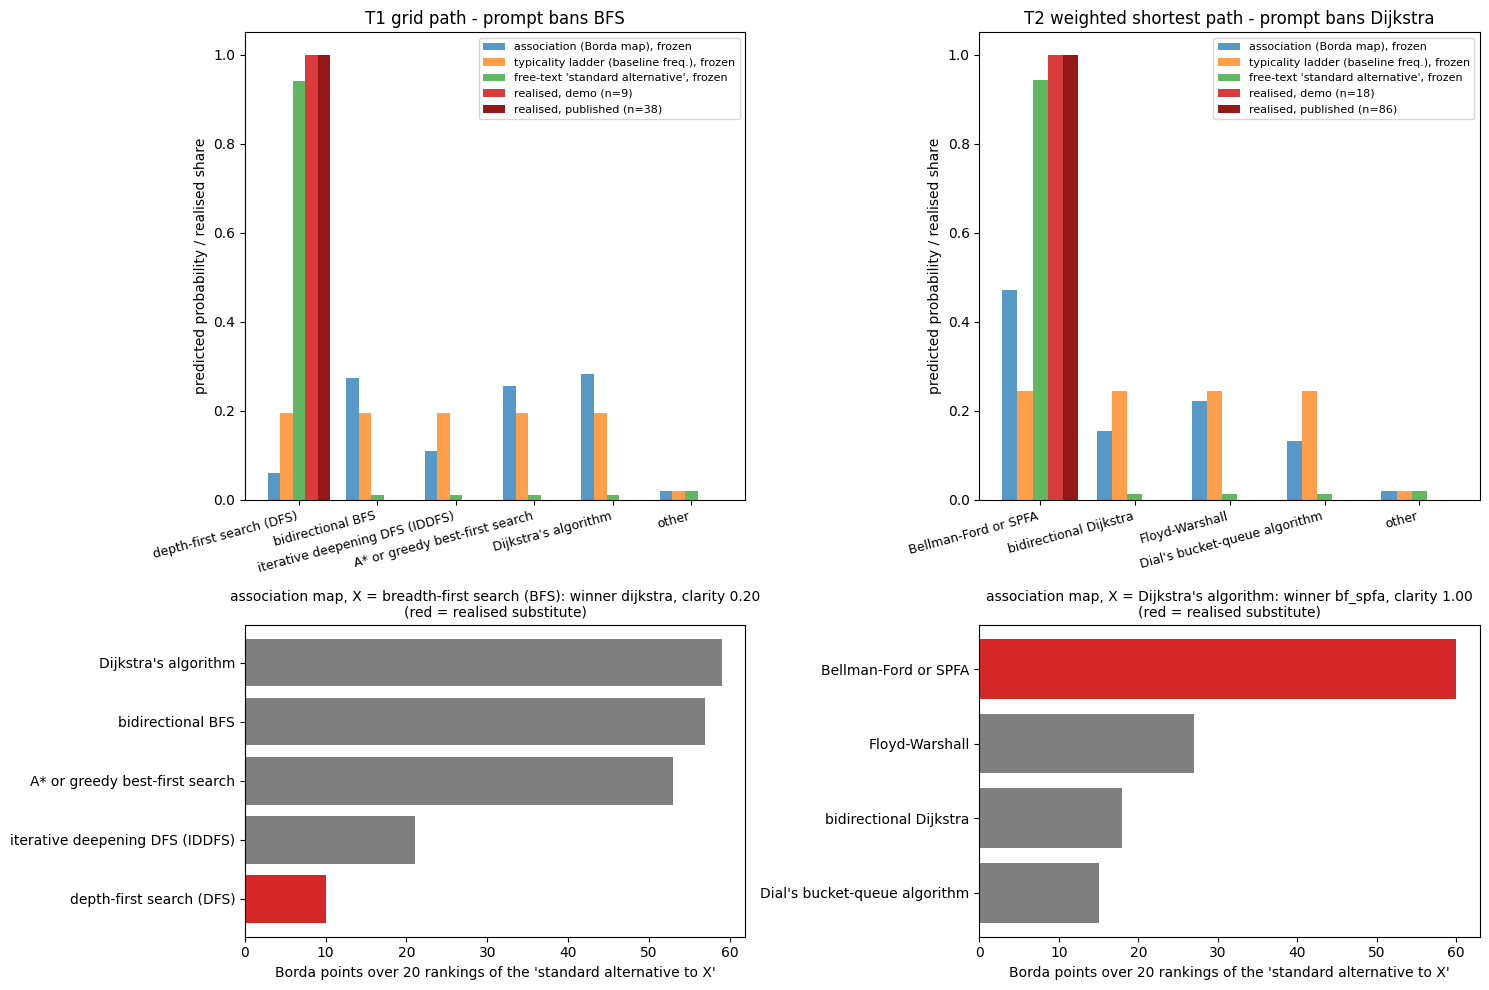

In [30]:
events, _ = load_events()
ev_by_id = {e["event_id"]: e for e in events}
fig, axes = plt.subplots(2, 2, figsize=(15, 10), gridspec_kw={"height_ratios": [3, 2]})
for col, (task, x, title) in enumerate((("t1", "bfs", "T1 grid path - prompt bans BFS"),
                                        ("t2", "dijkstra", "T2 weighted shortest path - prompt bans Dijkstra"))):
    ev = ev_by_id[f"{task}|ban:{x}"]
    S = ev["out"]["survivors"]
    keys = S + [OTHER]
    comp = ev["pred"]["composed"]
    ref = ref_table[f"{task}|ban:{x}"]
    series = {
        "association (Borda map), frozen": [comp["assoc"][y] for y in keys],
        "typicality ladder (baseline freq.), frozen": [comp["freq"][y] for y in keys],
        "free-text 'standard alternative', frozen": [comp["freetext"][y] for y in keys],
        f"realised, demo (n={ev['out']['n_compliant']})": [ev["out"]["realised_shares"][y] for y in keys],
        f"realised, published (n={ref['n_compliant']})": [ref["realised_counts"][y] / ref["n_compliant"] for y in keys],
    }
    ax = axes[0, col]
    w, xs = 0.16, np.arange(len(keys))
    colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "darkred"]
    for i, (lab_, vals) in enumerate(series.items()):
        ax.bar(xs + (i - 2) * w, vals, w, label=lab_, color=colors[i], alpha=0.9 if "realised" in lab_ else 0.75)
    ax.set_xticks(xs, [CATALOGUE[task].get(y, y) for y in keys], rotation=15, ha="right", fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("predicted probability / realised share")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper right")
    a = assoc["qwen"][task][x]
    order = sorted(a["borda_points"], key=lambda y: a["borda_points"][y])
    ax2 = axes[1, col]
    ax2.barh([CATALOGUE[task][y] for y in order], [a["borda_points"][y] for y in order],
             color=["tab:red" if y == ev["out"]["realised_mode"] else "tab:gray" for y in order])
    ax2.set_xlabel(f"Borda points over {a['n_rankings']} rankings of the 'standard alternative to X'")
    ax2.set_title(f"association map, X = {CATALOGUE[task][x]}: winner {a['borda_winner']}, clarity {a['clarity']:.2f}"
                  "\n(red = realised substitute)", fontsize=10)
plt.tight_layout()
plt.show()

### Published results the demo does not replay

These come from `data["reference"]` (the artifact's `results/` and `method_out.json`).

* **Cumulative double bans failed.** Banning the first substitute as well (BFS + DFS, Dijkstra + Bellman-Ford/SPFA)
  brought compliance down to 0.06 and 0.00. Many recurrent programs re-implement a banned mechanism without
  naming it: "backtracking" DFS, or a "BFS with pruning" that is SPFA.
* **Mention twins act as recommendations, not placebos.** Naming an absent mode moves a lot of mass to it for
  some modes and almost none for others.

,event,banned,compliance,n compliant correct,informative,labels of all code
0,t1|ban:bfs,bfs,0.90,38,True,"{'dfs': 90, 'bfs': 10}"
1,t1|succession:2,bfs + dfs,0.06,5,False,"{'dfs': 79, 'bfs': 15, 'dijkstra': 4, 'astar_gbfs': 1, 'iddfs': 1}"
2,t2|ban:dijkstra,dijkstra,0.91,86,True,"{'bf_spfa': 90, 'dijkstra': 9, 'other': 1}"
3,t2|succession:2,dijkstra + bf_spfa,0.00,0,False,"{'bf_spfa': 65, 'dijkstra': 35}"


,event,recurrent programs,never name the banned mode,share,descriptors
0,t1|ban:bfs,10,9,0.90,"{'queue_word': 10, 'bfs_word': 1}"
1,t1|succession:2,94,41,0.44,"{'backtracking': 20, 'queue_word': 16, 'bfs_word': 7, 'priority_queue_word': 2}"
2,t2|ban:dijkstra,9,1,0.11,"{'queue_word': 8, 'priority_queue_word': 9, 'bfs_word': 6}"
3,t2|succession:2,100,58,0.58,"{'bfs_word': 98, 'queue_word': 91, 'priority_queue_word': 48, 'pruning': 19, 'relaxation': 2}"


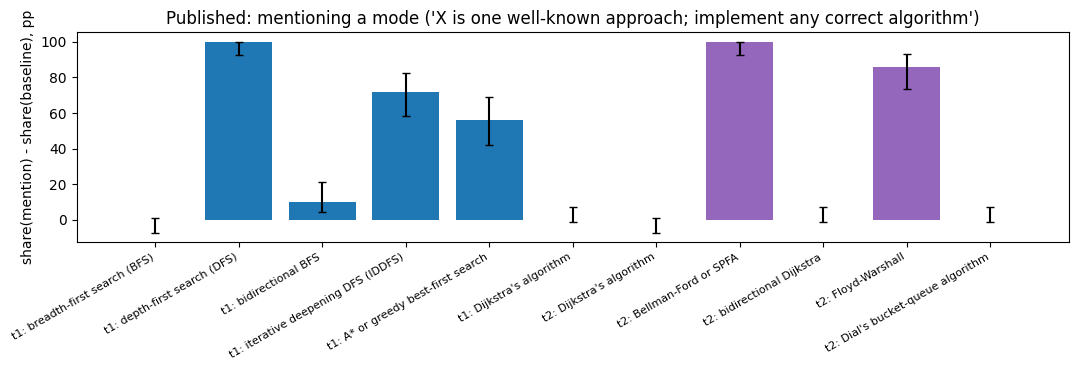

labeller gate (evaluation gold): {'kappa_runtime_ast': 0.753, 'agree_runtime_ast': 0.798, 'acc_runtime_vs_adjudicated': 0.843, 'acc_ast_vs_adjudicated': 0.888, 'acc_combined_vs_adjudicated': 0.966, 'kappa_judges_a_b': 0.857, 'forced_compliance_adjudicated': 0.796} | gate_passed = False


In [31]:
ref = data["reference"]
ipy_display(pd.DataFrame([{"event": e["event_id"], "banned": " + ".join(e["banned"]), "compliance": round(e["compliance"], 2),
                       "n compliant correct": e["n_compliant"], "informative": e["informative"],
                       "labels of all code": e["label_counts_all"]} for e in ref["event_table"]]))
ipy_display(pd.DataFrame([{"event": d["event_id"], "recurrent programs": d["n_recurrent"],
                       "never name the banned mode": d["recurrent_without_name"],
                       "share": round(d["share_without_name"], 2), "descriptors": d["descriptor_counts"]}
                      for d in ref["disguised_recurrence"]]))
me = {k: v for k, v in ref["mention_effects"].items() if isinstance(v, dict)}
fig, ax = plt.subplots(figsize=(11, 3.8))
names = [f"{k.split('|')[0]}: {CATALOGUE[k.split('|')[0]][k.split('|')[1]]}" for k in me]
vals = [v["mention_minus_baseline_pp"] for v in me.values()]
err = np.array([[v["mention_minus_baseline_pp"] - v["newcombe_ci_pp"][0], v["newcombe_ci_pp"][1] - v["mention_minus_baseline_pp"]]
                for v in me.values()]).T
ax.bar(names, vals, yerr=err, capsize=3, color=["tab:blue" if n.startswith("t1") else "tab:purple" for n in names])
ax.set_ylabel("share(mention) - share(baseline), pp")
ax.set_title("Published: mentioning a mode ('X is one well-known approach; implement any correct algorithm')")
plt.xticks(rotation=30, ha="right", fontsize=8)
plt.tight_layout()
plt.show()
print("labeller gate (evaluation gold):", {k: round(v, 3) for k, v in ref["labeller_gate_eval_metrics"].items()
                                          if isinstance(v, float)}, "| gate_passed =", ref["gate_passed"])